In [2]:
import os
import numpy as np
import pandas as pd

from allensdk.brain_observatory.ecephys.ecephys_project_cache import EcephysProjectCache

c:\Users\T430\miniforge3\envs\allensdk\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [19]:

output_dir = r"D:\capstone"

os.makedirs(output_dir, exist_ok=True)

manifest_path = os.path.join(output_dir, "manifest.json")

In [20]:
cache = EcephysProjectCache.from_warehouse(
    manifest=manifest_path
)


In [24]:
sessions = cache.get_session_table()
sessions.head()


,published_at,specimen_id,session_type,age_in_days,sex,full_genotype,unit_count,channel_count,probe_count,ecephys_structure_acronyms
id,,,,,,,,,,
715093703,2019-10-03T00:00:00Z,699733581,brain_observatory_1.1,118.0,M,Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,884,2219,6,"[CA1, VISrl, nan, PO, LP, LGd, CA3, DG, VISl, ..."
719161530,2019-10-03T00:00:00Z,703279284,brain_observatory_1.1,122.0,M,Sst-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,755,2214,6,"[TH, Eth, APN, POL, LP, DG, CA1, VISpm, nan, N..."
721123822,2019-10-03T00:00:00Z,707296982,brain_observatory_1.1,125.0,M,Pvalb-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,444,2229,6,"[MB, SCig, PPT, NOT, DG, CA1, VISam, nan, LP, ..."
732592105,2019-10-03T00:00:00Z,717038288,brain_observatory_1.1,100.0,M,wt/wt,824,1847,5,"[grey, VISpm, nan, VISp, VISl, VISal, VISrl]"
737581020,2019-10-03T00:00:00Z,718643567,brain_observatory_1.1,108.0,M,wt/wt,568,2218,6,"[grey, VISmma, nan, VISpm, VISp, VISl, VISrl]"


In [27]:
762120172 in sessions.index, 793224716 in sessions.index

(True, True)

In [29]:
target_sessions = sessions.iloc[[24, 42]]
target_sessions

,published_at,specimen_id,session_type,age_in_days,sex,full_genotype,unit_count,channel_count,probe_count,ecephys_structure_acronyms
id,,,,,,,,,,
762120172,2019-10-03T00:00:00Z,745276236,brain_observatory_1.1,100.0,M,Vip-IRES-Cre/wt;Ai32(RCL-ChR2(H134R)_EYFP)/wt,717,1860,5,"[grey, VISal, nan, VISl, VISp, VIS, VISam]"
793224716,2019-10-03T00:00:00Z,769319624,functional_connectivity,120.0,M,wt/wt,781,2229,6,"[APN, NOT, MB, DG, CA1, VIS, nan, Eth, LP, SGN..."


In [28]:
session_24 = cache.get_session_data(762120172)
session_42 = cache.get_session_data(793224716)

Downloading: 100%|██████████| 2.87G/2.87G [01:07<00:00, 42.6MB/s]
c:\Users\T430\miniforge3\envs\allensdk\lib\site-packages\hdmf\spec\namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning if these versions are compatible.
  self.warn_for_ignored_namespaces(ignored_namespaces)
Downloading: 100%|██████████| 2.69G/2.69G [00:42<00:00, 63.8MB/s]
c:\Users\T430\miniforge3\envs\allensdk\lib\site-packages\hdmf\spec\namespace.py:620: UserWarning: Ignoring the following cached namespace(s) because another version is already loaded:
core - cached version: 2.2.2, loaded version: 2.7.0
The loaded extension(s) may not be compatible with the cached extension(s) in the file. Please check the extension documentation and ignore this warning i

In [59]:
units = cache.get_units()
units_24 = units[units["ecephys_session_id"] == 762120172]
units_42 = units[units["ecephys_session_id"] == 793224716]
units_24_filtered = units_24[
    units_24["ecephys_structure_acronym"].isin(["VISal", "VISp"])
]

units_42_filtered = units_42[
    units_42["ecephys_structure_acronym"].isin(["VISal", "VISp"])
]



In [45]:
stim_42 = session_42.stimulus_presentations

dg_contrast_42 = stim_42[
    stim_42["stimulus_name"] == "drifting_gratings_contrast"
].copy()

dg_75_42 = stim_42[
    stim_42["stimulus_name"] == "drifting_gratings_75_repeats"
].copy()

print("contrast:", dg_contrast_42.shape)
print("75 repeats:", dg_75_42.shape)

contrast: (540, 19)
75 repeats: (600, 19)


In [46]:
print("contrast orientations:")
print(dg_contrast_42["orientation"].unique())

print("\n75 repeats orientations:")
print(dg_75_42["orientation"].unique())

contrast orientations:
[90.0 45.0 135.0 0.0]

75 repeats orientations:
[90.0 135.0 45.0 0.0]


In [47]:
print("\ncontrast counts:")
print(dg_contrast_42["orientation"].value_counts())

print("\n75-repeat counts:")
print(dg_75_42["orientation"].value_counts())


contrast counts:
90.0     135
45.0     135
135.0    135
0.0      135
Name: orientation, dtype: int64

75-repeat counts:
90.0     150
135.0    150
45.0     150
0.0      150
Name: orientation, dtype: int64


In [38]:
stim = session_24.stimulus_presentations

drifting_gratings = stim[
    stim["stimulus_name"] == "drifting_gratings"
].copy()

print(drifting_gratings.shape)
print(drifting_gratings[["orientation", "start_time", "stop_time", "duration"]].head())

(630, 16)
                         orientation   start_time    stop_time  duration
stimulus_presentation_id                                                
3798                           225.0  1592.948984  1594.950644   2.00166
3799                           135.0  1595.951487  1597.953167   2.00168
3800                           225.0  1598.954004  1600.955644   2.00164
3801                            45.0  1601.956507  1603.958177   2.00167
3802                           135.0  1604.959034  1606.960684   2.00165


In [40]:
print(drifting_gratings["orientation"].unique())

[225.0 135.0 45.0 0.0 270.0 90.0 'null' 315.0 180.0]


In [41]:
orientations = sorted(
    drifting_gratings[
        pd.to_numeric(drifting_gratings["orientation"], errors="coerce").notna()
    ]["orientation"].astype(float).unique()
)

print(orientations)

[0.0, 45.0, 90.0, 135.0, 180.0, 225.0, 270.0, 315.0]


In [48]:
orientations = [0.0, 45.0, 90.0, 135.0]

# Session 24
stim_24 = session_24.stimulus_presentations

dg_24 = stim_24[
    (stim_24["stimulus_name"] == "drifting_gratings") &
    (stim_24["orientation"].isin(orientations))
].copy()

# Session 42
stim_42 = session_42.stimulus_presentations

dg_42 = stim_42[
    (stim_42["stimulus_name"] == "drifting_gratings_75_repeats") &
    (stim_42["orientation"].isin(orientations))
].copy()

In [49]:
print("Session 24:")
print(dg_24["orientation"].value_counts().sort_index())

print("\nSession 42:")
print(dg_42["orientation"].value_counts().sort_index())

Session 24:
0.0      75
45.0     75
90.0     75
135.0    75
Name: orientation, dtype: int64

Session 42:
0.0      150
45.0     150
90.0     150
135.0    150
Name: orientation, dtype: int64


In [50]:
dg_24["session"] = 24
dg_42["session"] = 42
dg_24["presentation_id"] = dg_24.index
dg_42["presentation_id"] = dg_42.index
all_presentations = pd.concat(
    [dg_24, dg_42],
    ignore_index=True
)
all_presentations.shape

(900, 21)

In [51]:
all_presentations[
    ["session", "presentation_id", "orientation",
     "start_time", "stop_time", "duration"]
].head(10)

,session,presentation_id,orientation,start_time,stop_time,duration
0,24,3799,135.0,1595.951487,1597.953167,2.00168
1,24,3801,45.0,1601.956507,1603.958177,2.00167
2,24,3802,135.0,1604.959034,1606.960684,2.00165
3,24,3803,0.0,1607.961517,1609.963197,2.00168
4,24,3805,90.0,1613.966537,1615.968197,2.00166
5,24,3806,135.0,1616.969044,1618.970714,2.00167
6,24,3807,135.0,1619.971557,1621.973237,2.00168
7,24,3808,45.0,1622.974054,1624.975724,2.00167
8,24,3809,0.0,1625.976577,1627.978247,2.00167
9,24,3810,45.0,1628.979114,1630.980734,2.00162


In [60]:
def get_firing_rates(session, units, stimulus_table, session_number):
    
    results = []

    for unit_id in units.index:
        
        spike_times = session.spike_times[unit_id]

        for _, presentation in stimulus_table.iterrows():
            
            start = presentation["start_time"]
            stop = presentation["stop_time"]

            spike_count = np.sum(
                (spike_times >= start) &
                (spike_times < stop)
            )

            firing_rate = spike_count / (stop - start)

            results.append({
                "session": session_number,
                "unit_id": unit_id,
                "orientation": presentation["orientation"],
                "presentation_id": presentation["presentation_id"],
                "firing_rate": firing_rate
            })

    return pd.DataFrame(results)

fr_24 = get_firing_rates(
    session_24,
    units_24_filtered,
    dg_24,
    24
)

fr_42 = get_firing_rates(
    session_42,
    units_42_filtered,
    dg_42,
    42
)

In [61]:
firing_rates = pd.concat(
    [fr_24, fr_42],
    ignore_index=True
)

In [62]:
summary = (
    firing_rates
    .groupby(["session", "unit_id", "orientation"])["firing_rate"]
    .agg(["mean", "std", "count"])
    .reset_index()
)

summary["sem"] = summary["std"] / np.sqrt(summary["count"])

summary["ci_lower"] = summary["mean"] - 1.96 * summary["sem"]
summary["ci_upper"] = summary["mean"] + 1.96 * summary["sem"]

In [63]:
summary.head()

,session,unit_id,orientation,mean,std,count,sem,ci_lower,ci_upper
0,24,951869857,0.0,0.119900,0.257635,75,0.029749,0.061592,0.178208
1,24,951869857,45.0,0.159866,0.319783,75,0.036925,0.087492,0.232240
2,24,951869857,90.0,0.093255,0.212482,75,0.024535,0.045165,0.141344
3,24,951869857,135.0,0.133222,0.413383,75,0.047733,0.039665,0.226779
4,24,951869889,0.0,0.952542,1.795992,75,0.207383,0.546071,1.359013


In [64]:
summary[summary["unit_id"] == summary["unit_id"].iloc[0]]

,session,unit_id,orientation,mean,std,count,sem,ci_lower,ci_upper
0,24,951869857,0.0,0.119900,0.257635,75,0.029749,0.061592,0.178208
1,24,951869857,45.0,0.159866,0.319783,75,0.036925,0.087492,0.232240
2,24,951869857,90.0,0.093255,0.212482,75,0.024535,0.045165,0.141344
3,24,951869857,135.0,0.133222,0.413383,75,0.047733,0.039665,0.226779


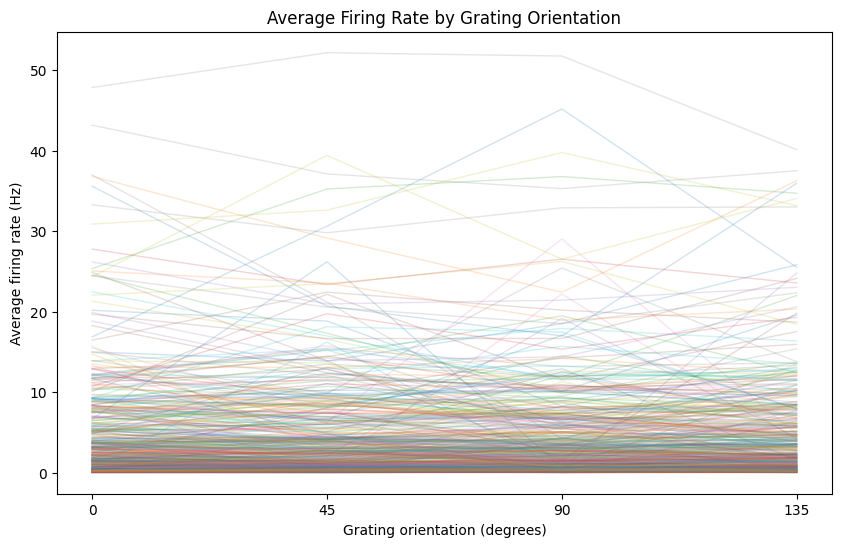

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

for unit_id in summary["unit_id"].unique():
    
    unit_data = summary[summary["unit_id"] == unit_id].sort_values("orientation")
    
    plt.plot(
        unit_data["orientation"],
        unit_data["mean"],
        alpha=0.2,
        linewidth=1
    )

plt.xlabel("Grating orientation (degrees)")
plt.ylabel("Average firing rate (Hz)")
plt.title("Average Firing Rate by Grating Orientation")
plt.xticks([0, 45, 90, 135])
plt.show()

In [66]:
avg_firing_table = summary.pivot(
    index=["session", "unit_id"],
    columns="orientation",
    values="mean"
).reset_index()

avg_firing_table.columns.name = None

avg_firing_table

,session,unit_id,0.0,45.0,90.0,135.0
0,24,951869857,0.119900,0.159866,0.093255,0.133222
1,24,951869889,0.952542,0.679433,3.590321,0.719397
2,24,951869927,5.415479,3.037461,0.506243,2.178179
3,24,951870013,0.039967,0.079933,0.033305,0.079933
4,24,951870077,2.457951,0.805993,1.025807,1.398825
...,...,...,...,...,...,...
421,42,951071078,0.169859,0.396333,0.562861,0.206494
422,42,951071086,6.497914,8.139843,9.288881,7.114047
423,42,951071096,0.046628,0.096586,0.119900,0.099917
424,42,951071115,1.795169,0.479598,2.258106,1.665272


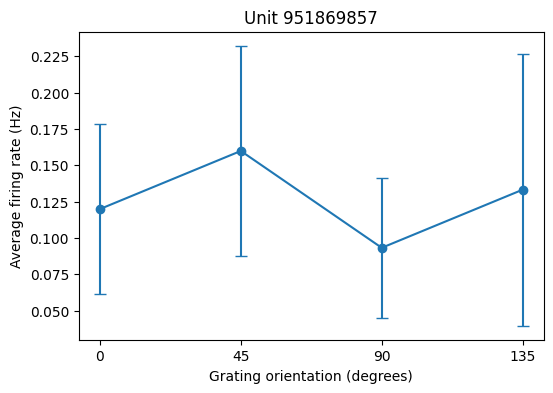

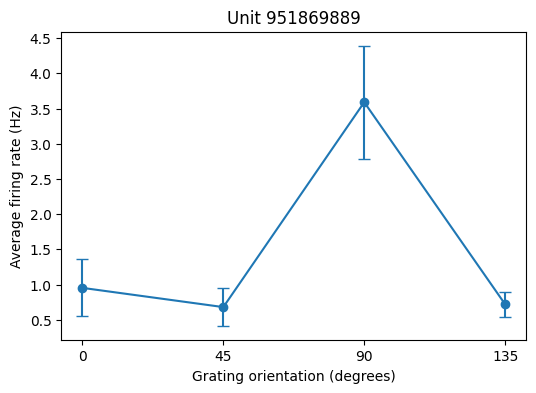

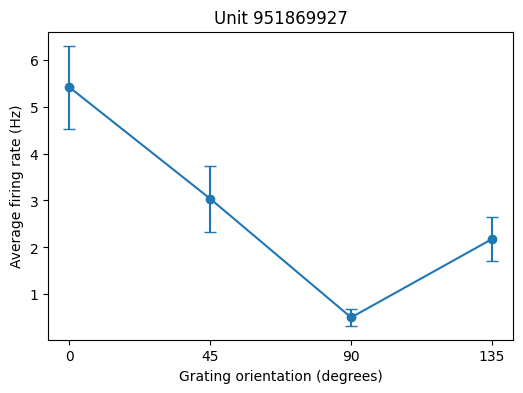

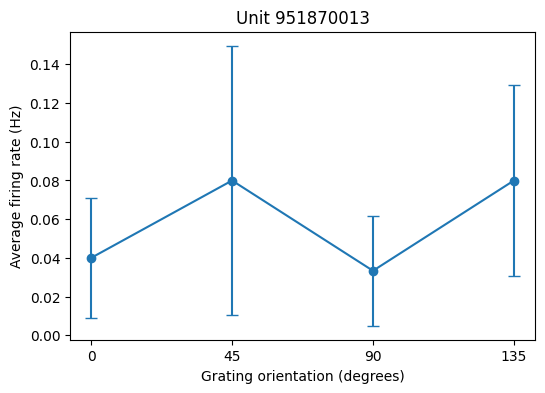

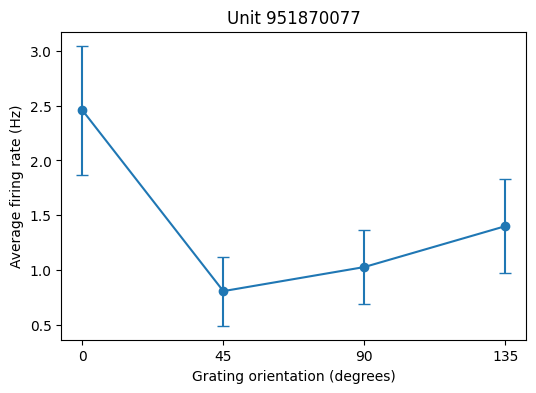

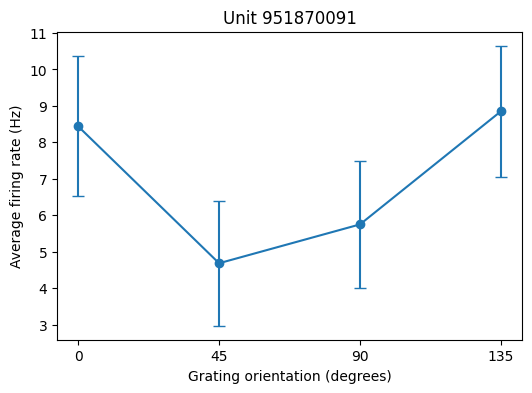

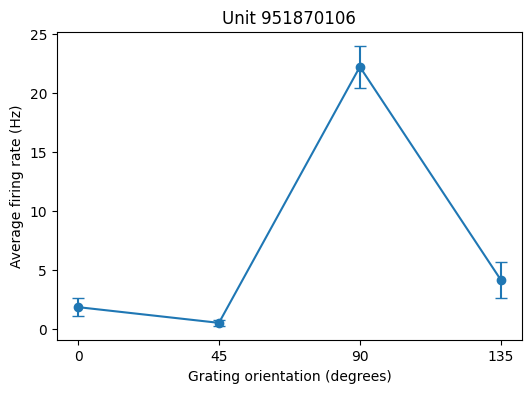

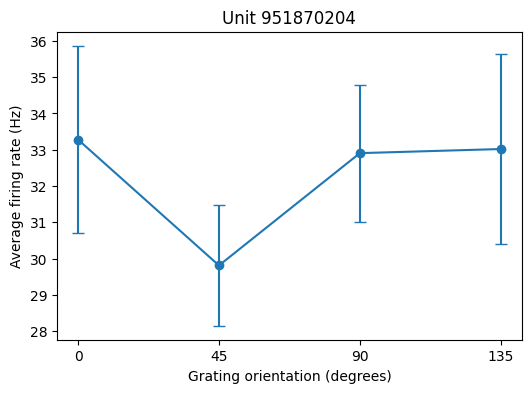

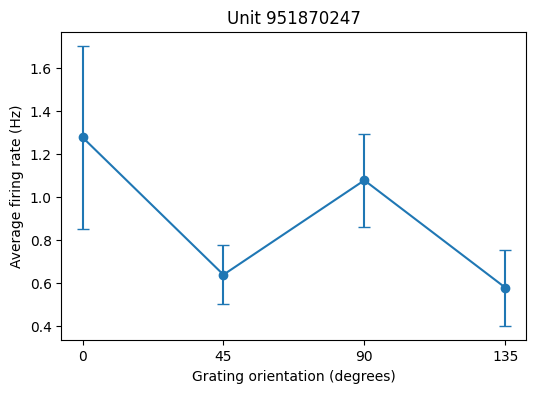

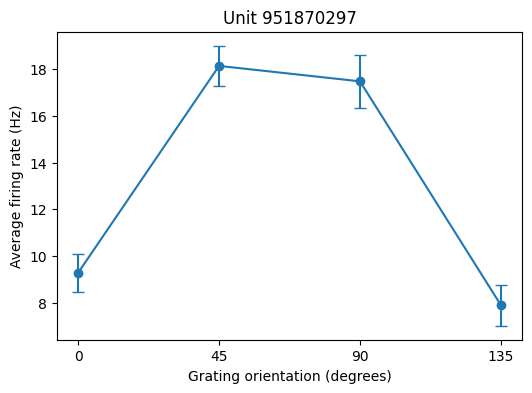

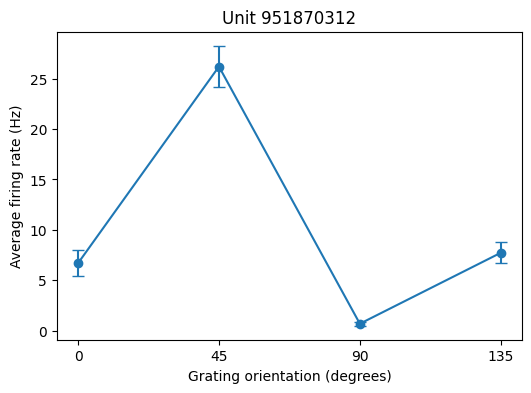

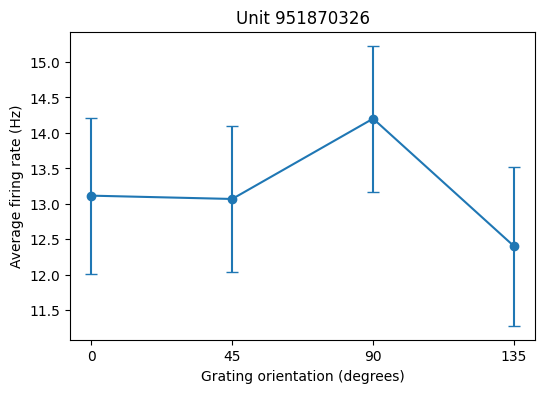

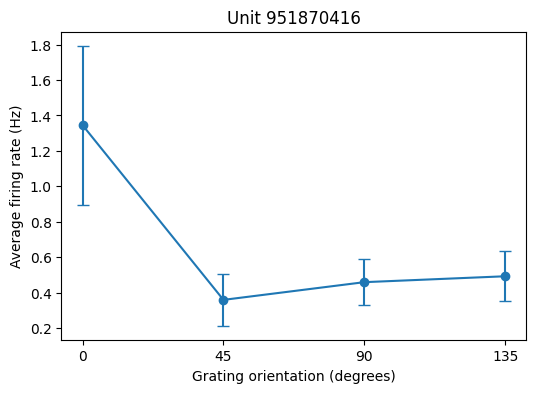

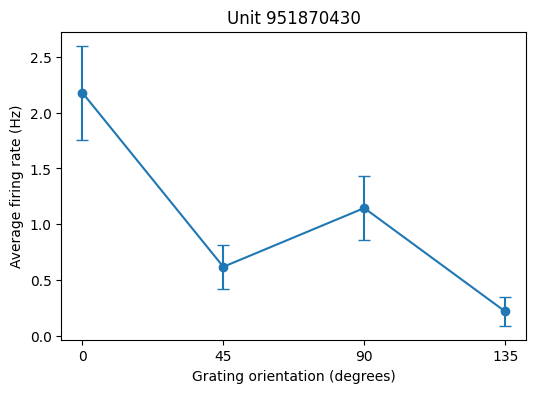

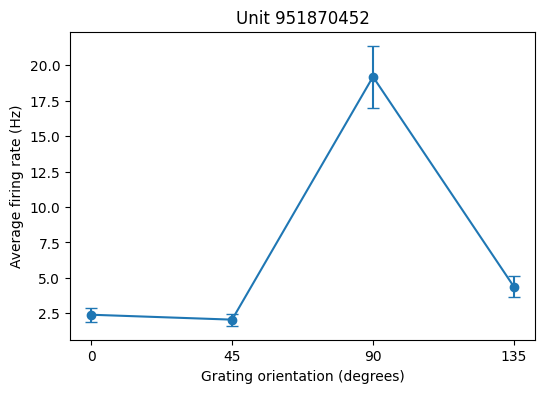

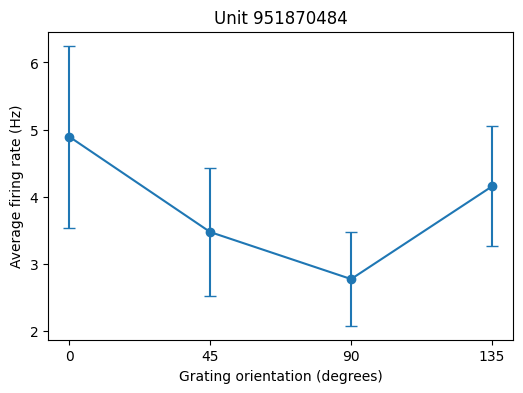

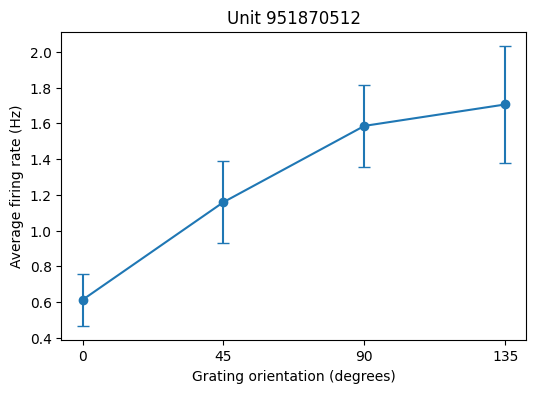

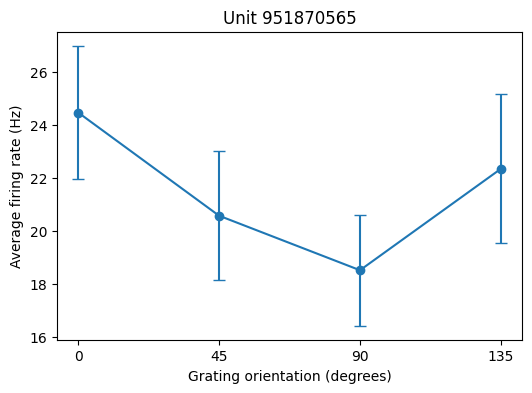

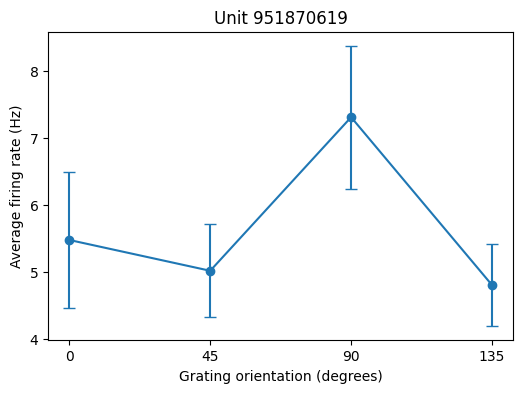

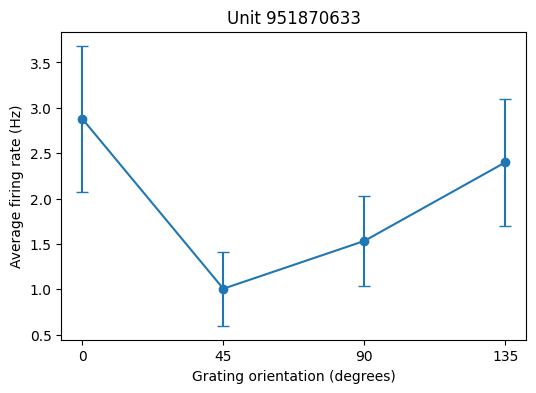

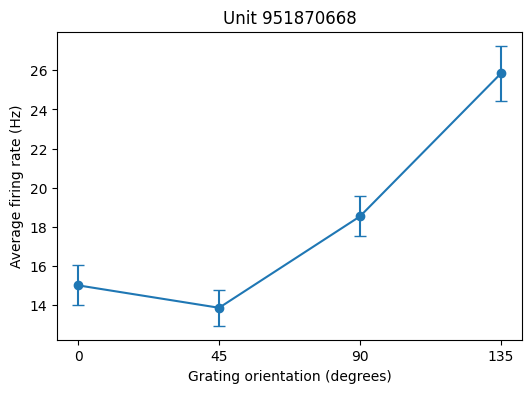

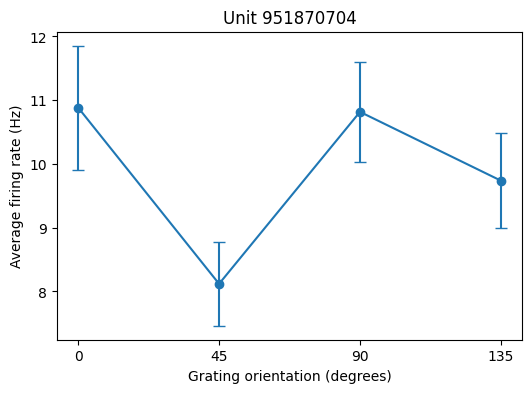

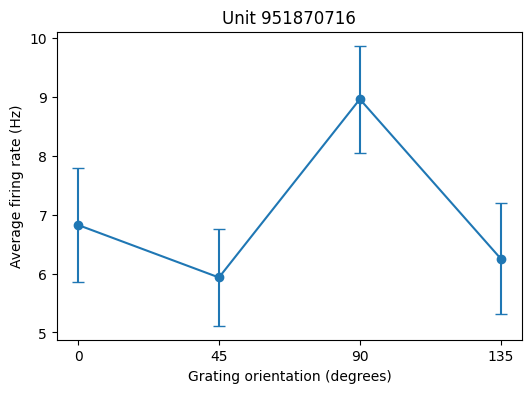

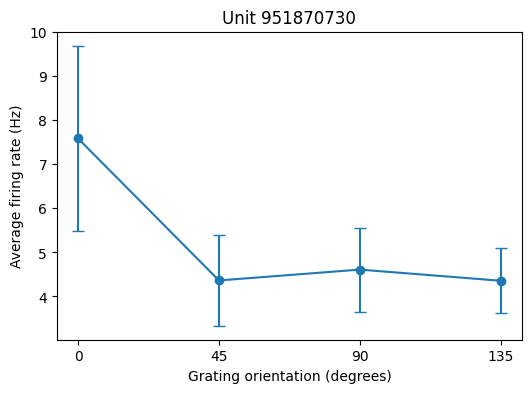

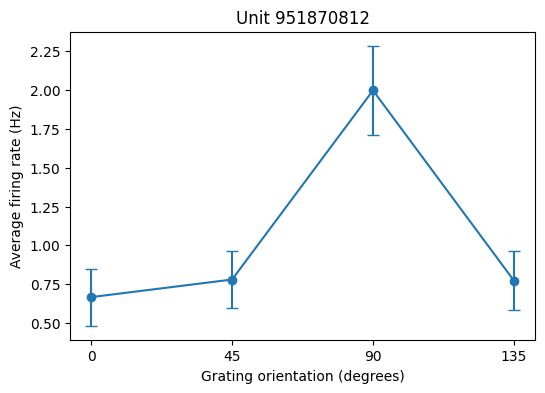

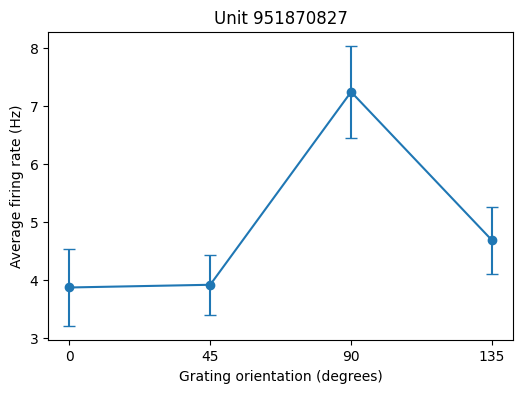

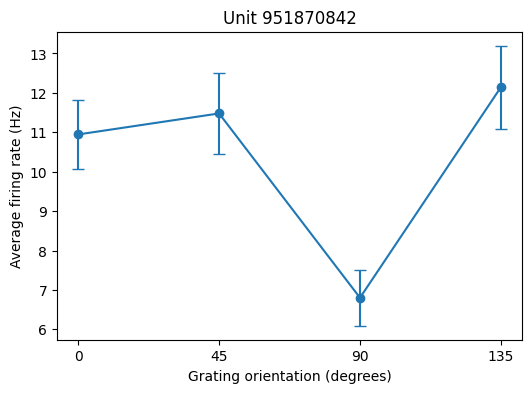

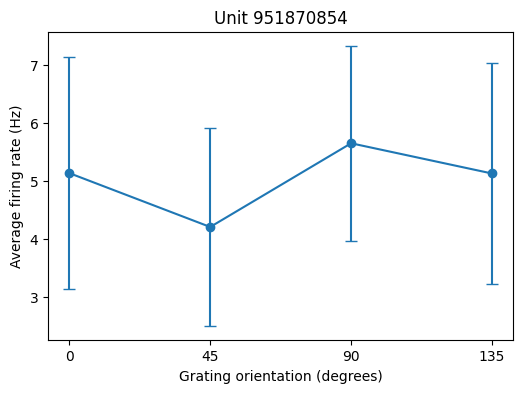

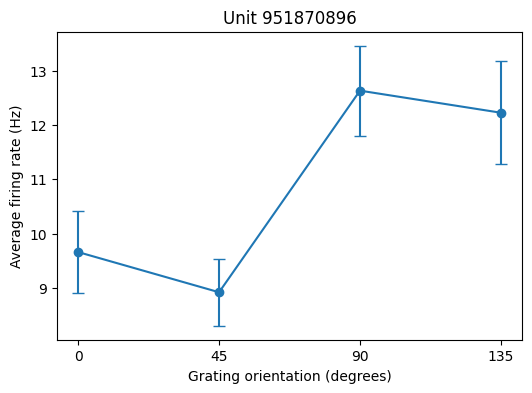

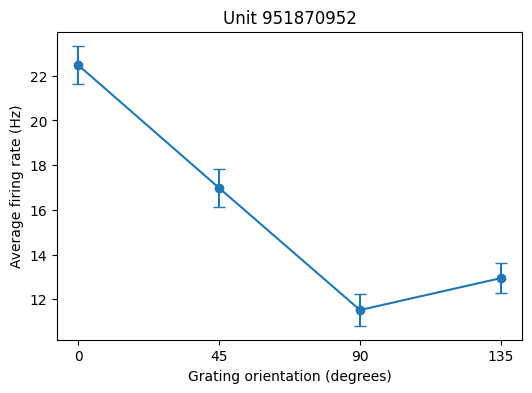

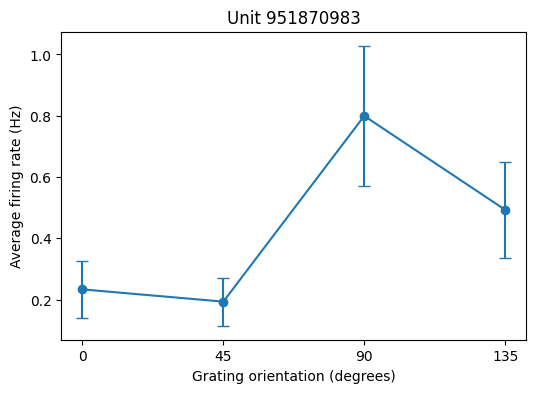

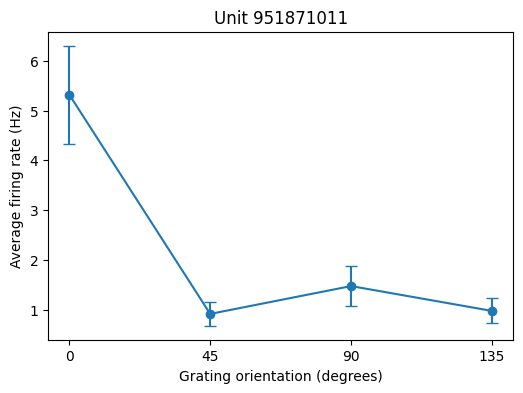

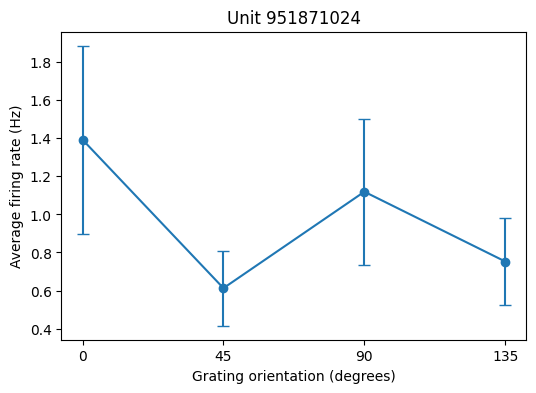

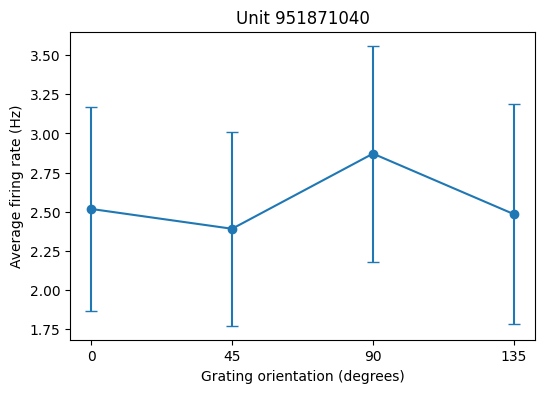

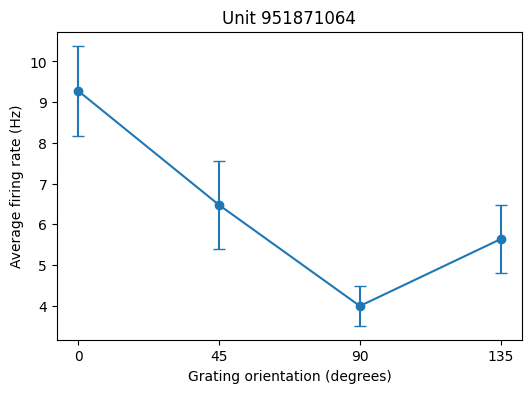

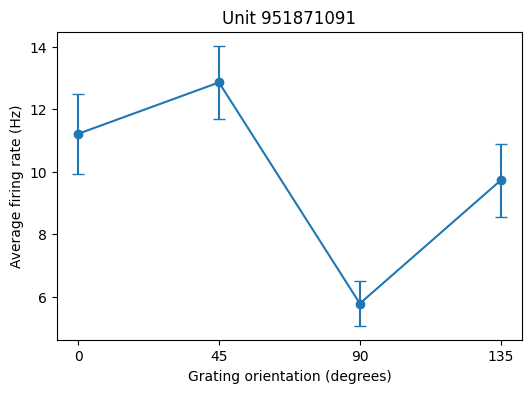

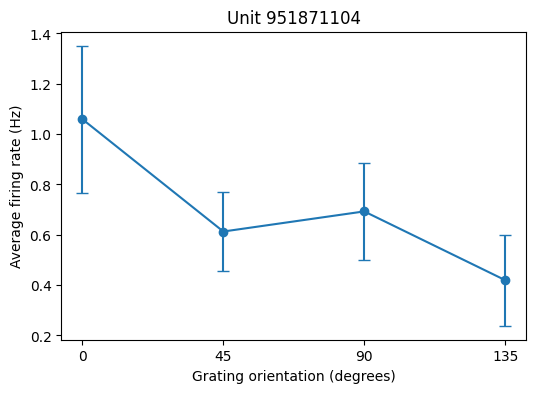

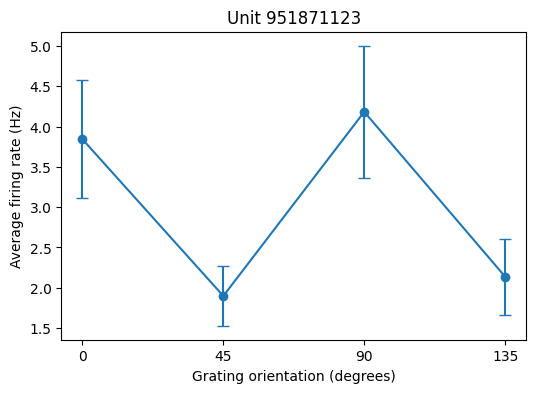

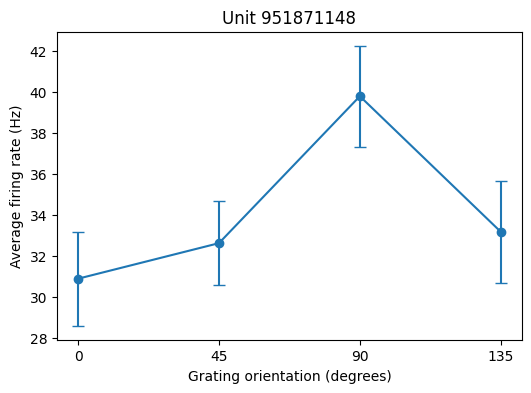

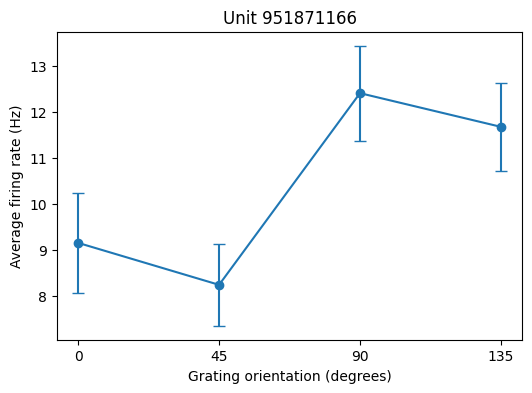

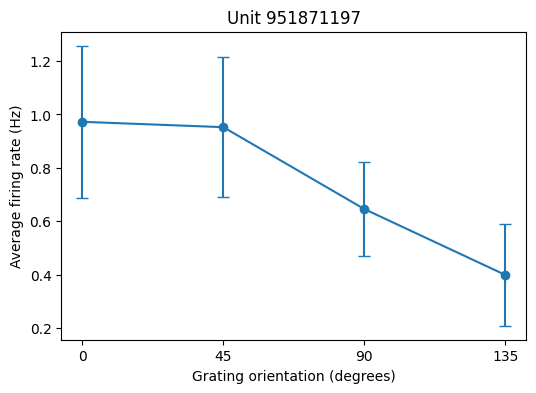

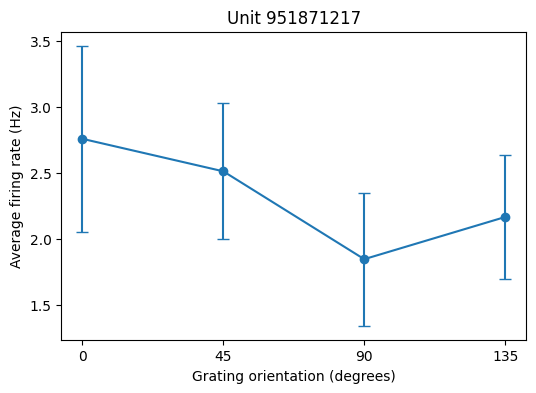

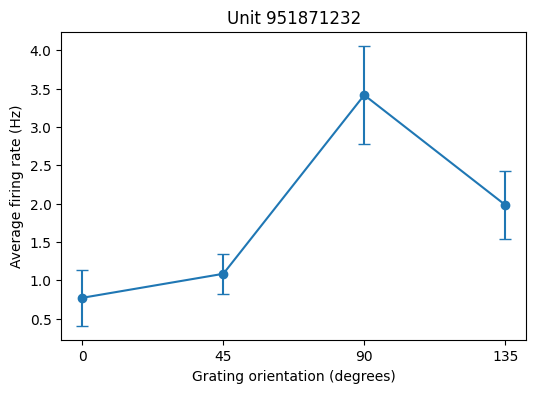

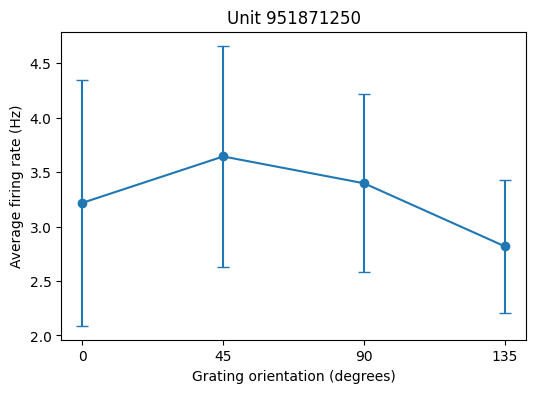

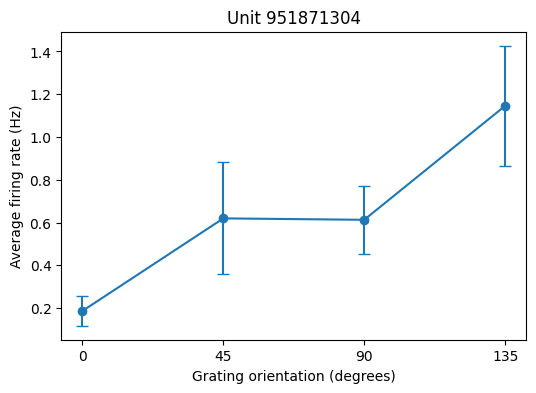

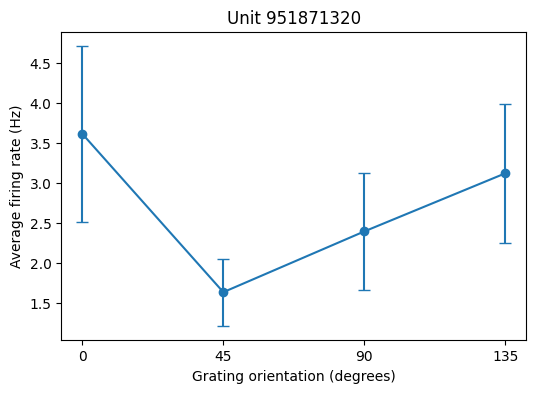

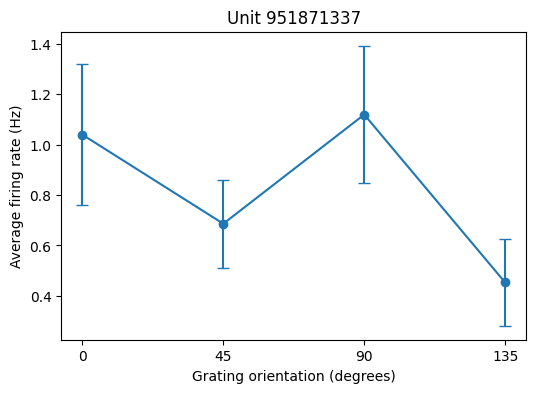

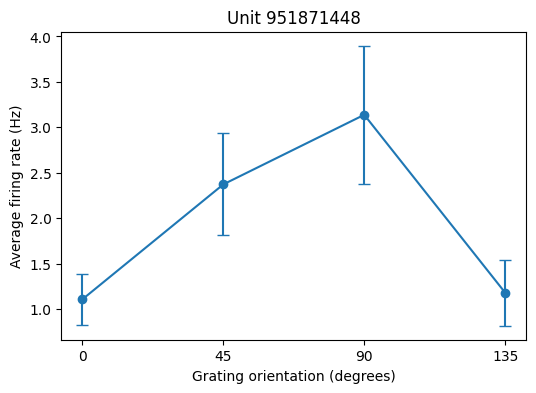

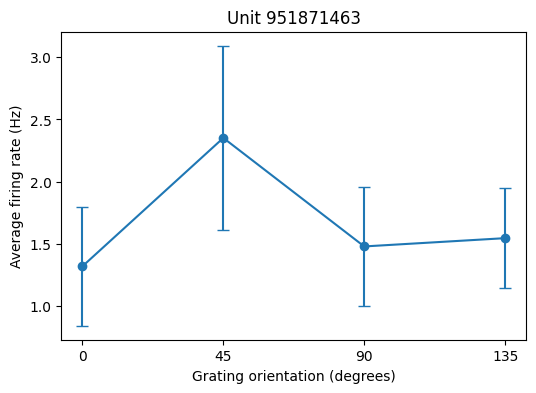

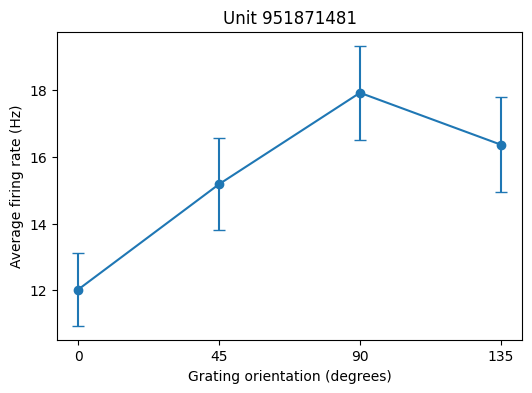

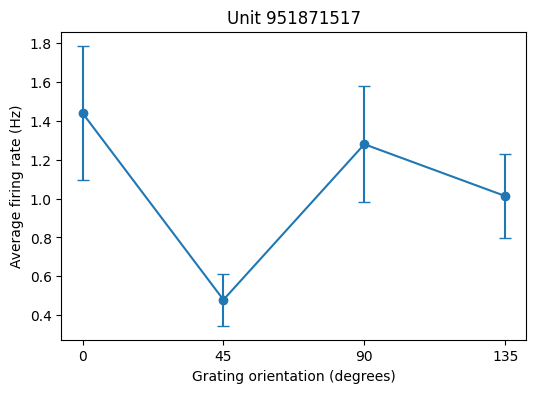

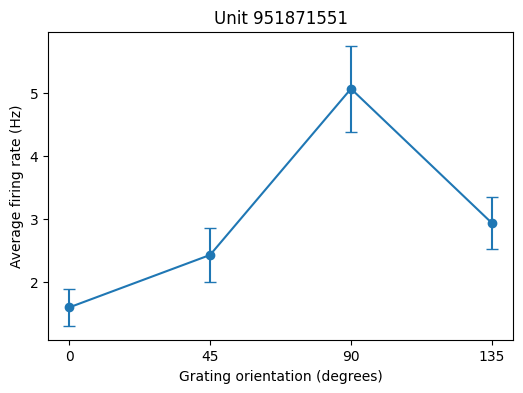

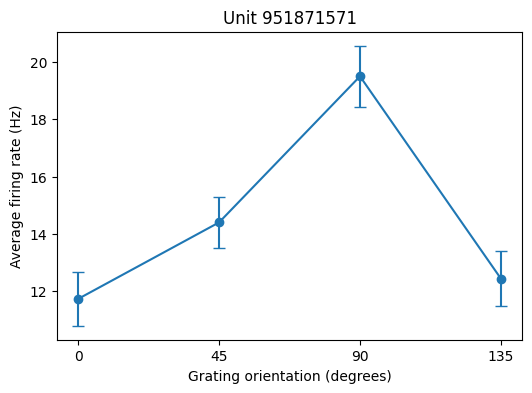

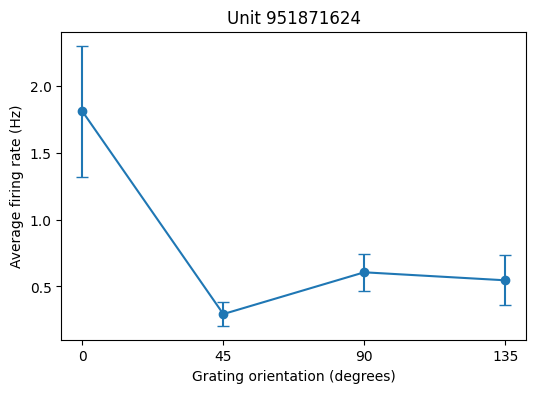

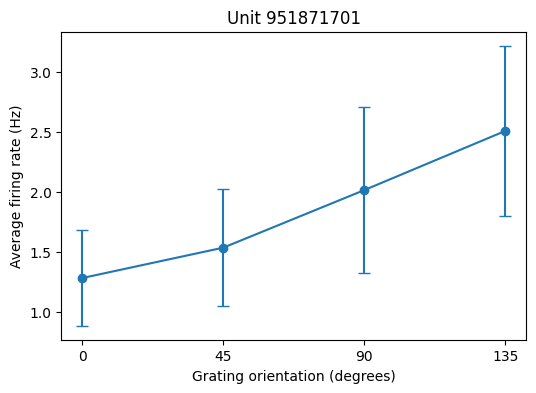

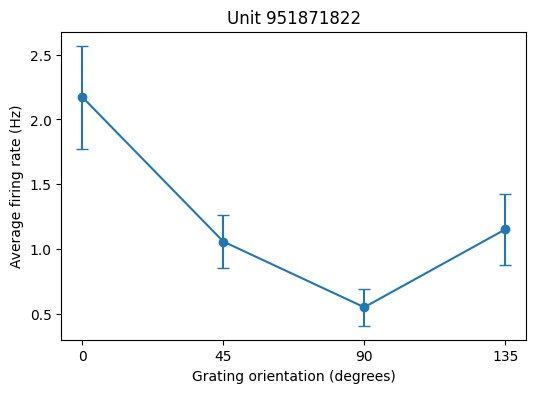

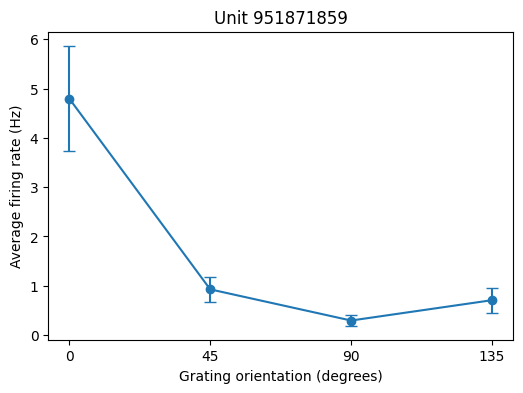

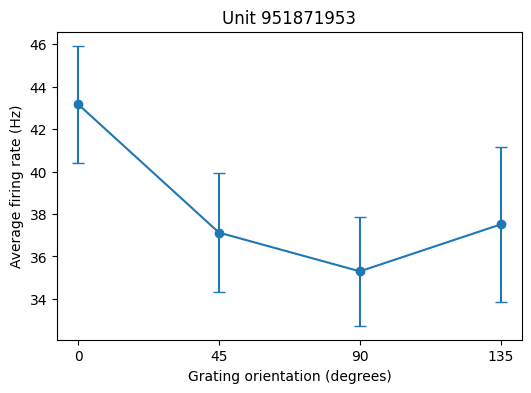

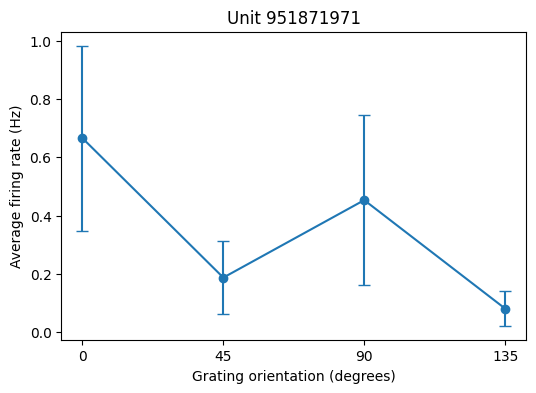

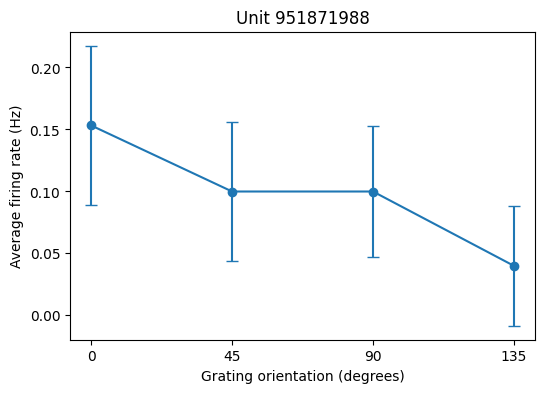

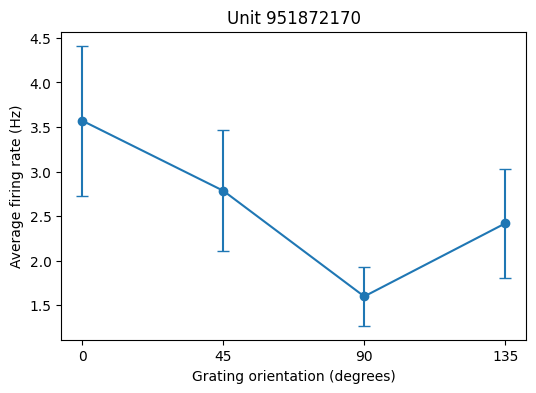

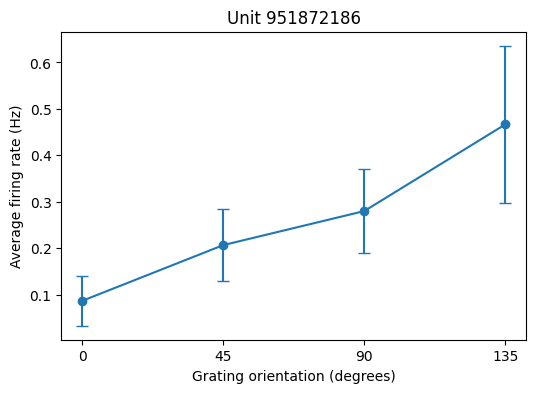

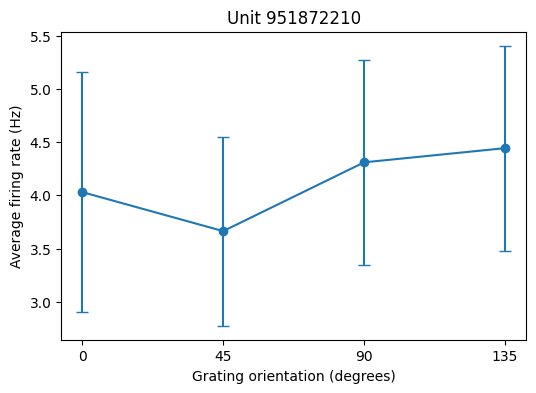

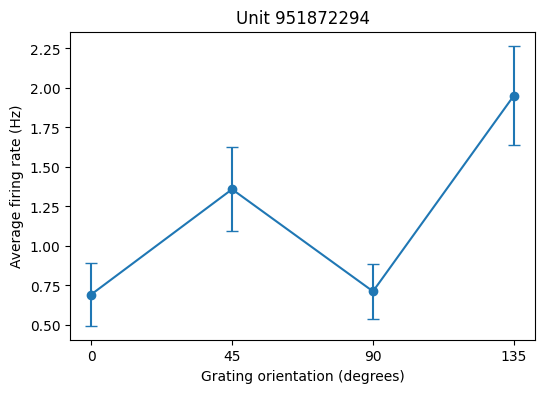

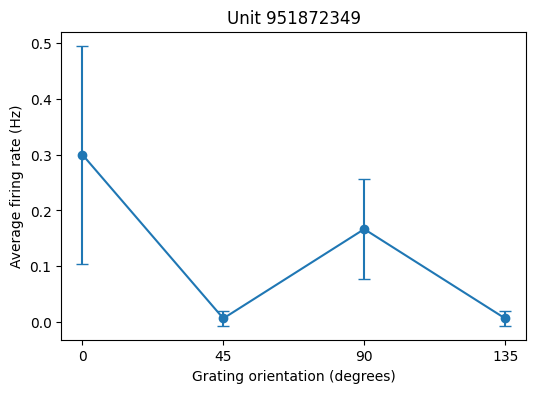

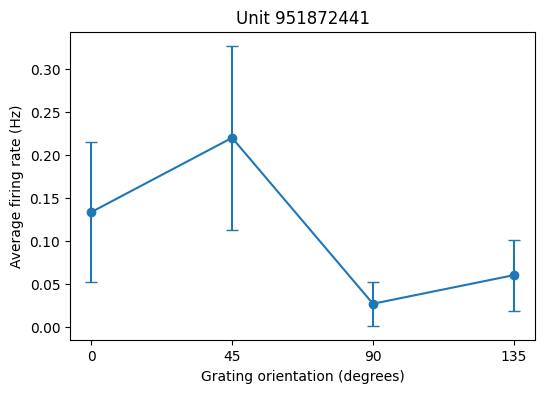

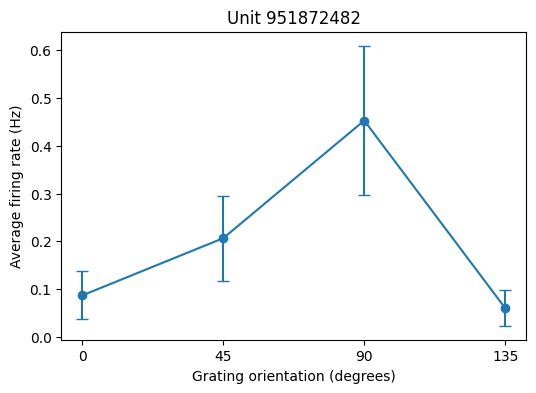

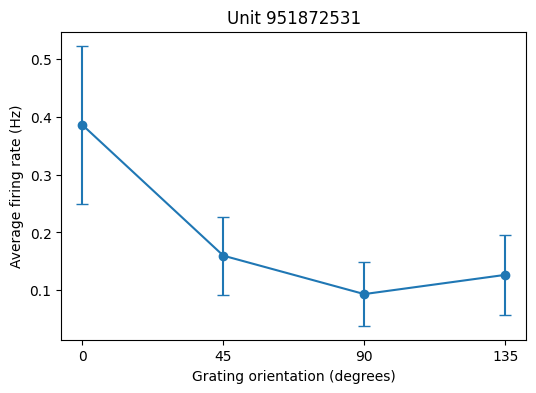

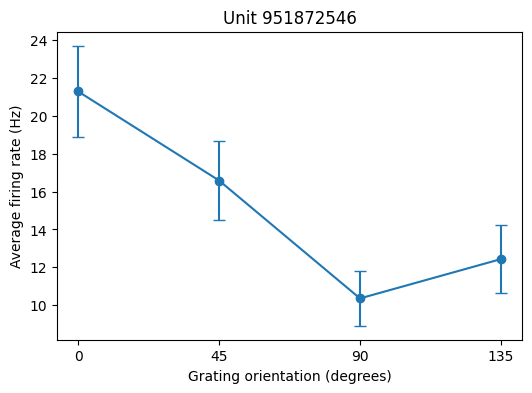

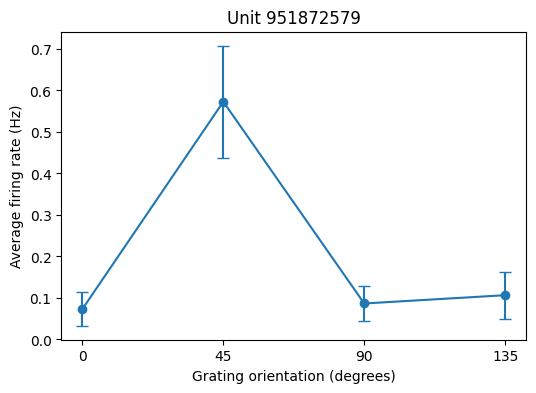

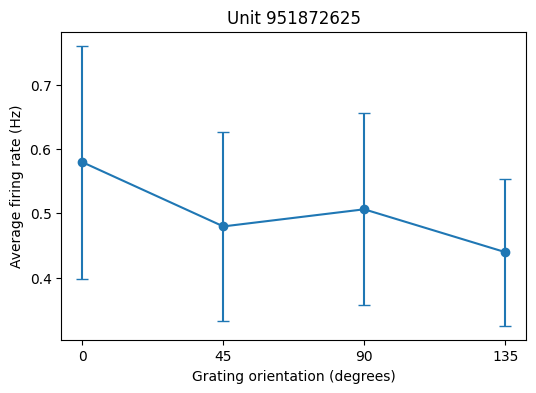

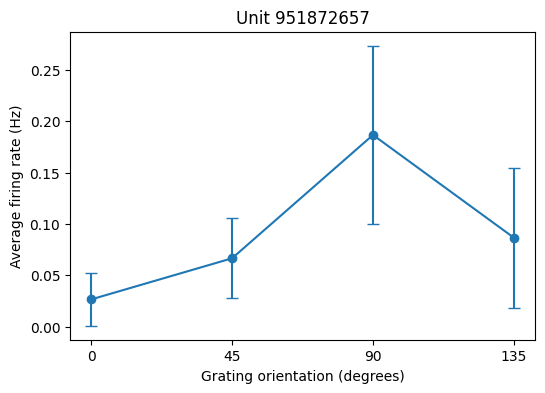

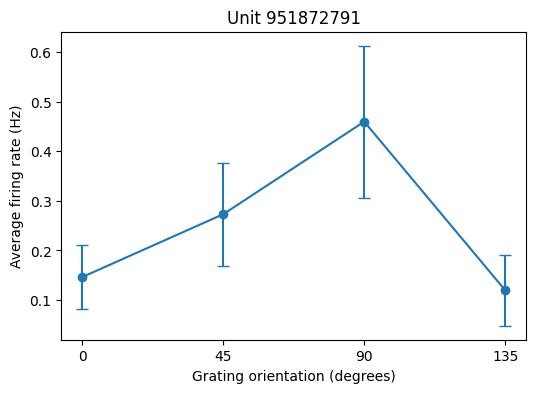

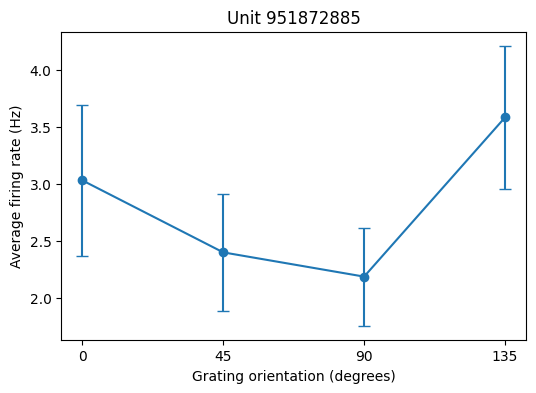

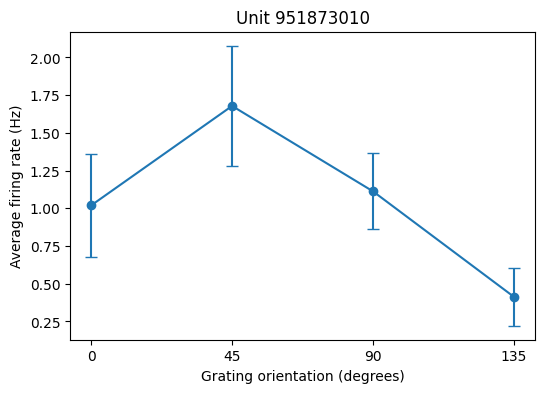

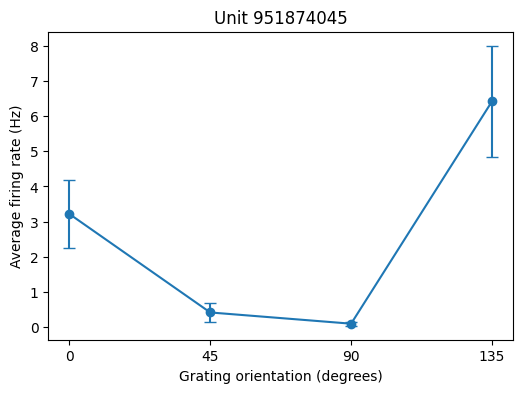

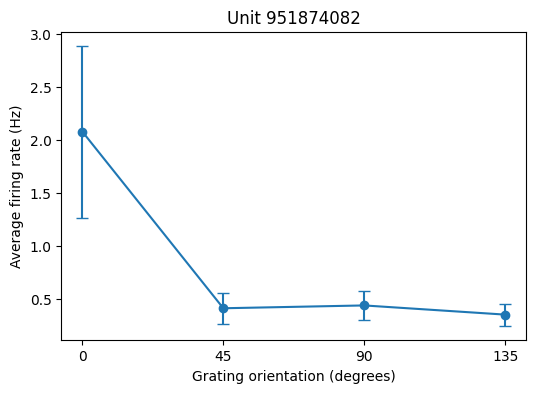

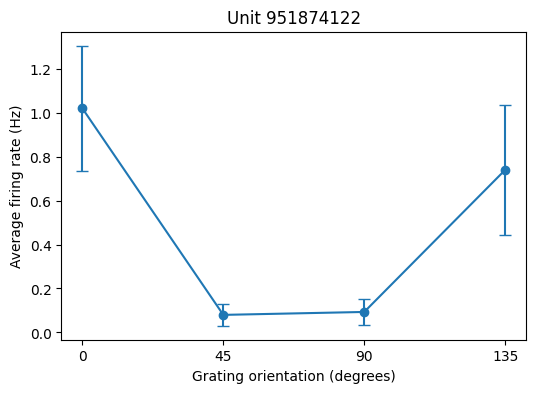

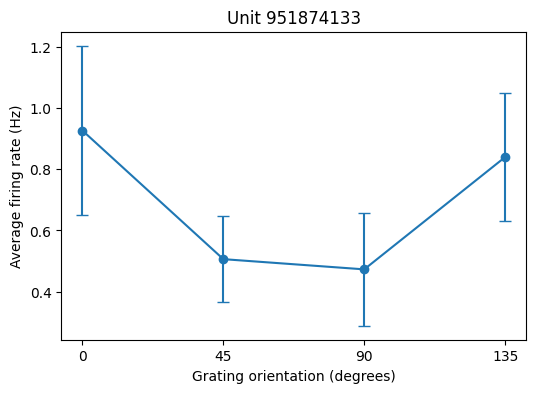

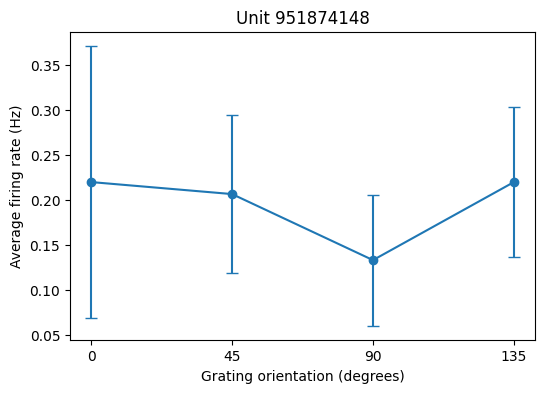

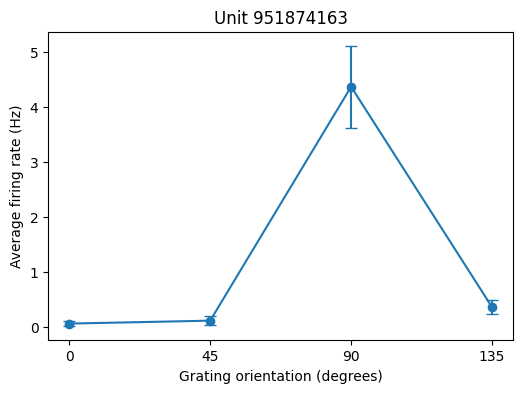

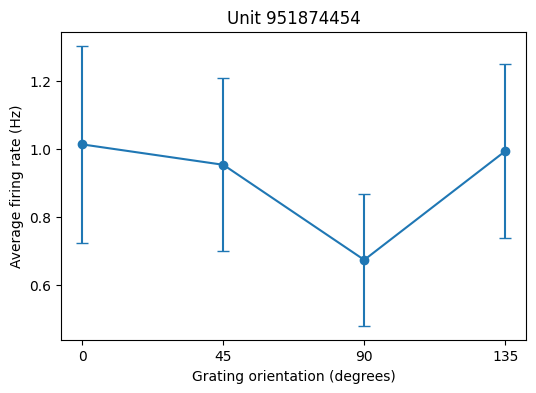

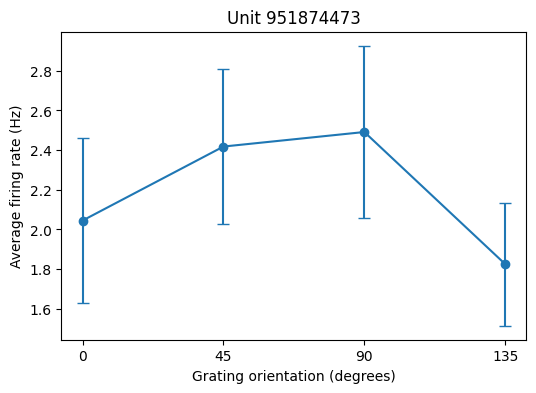

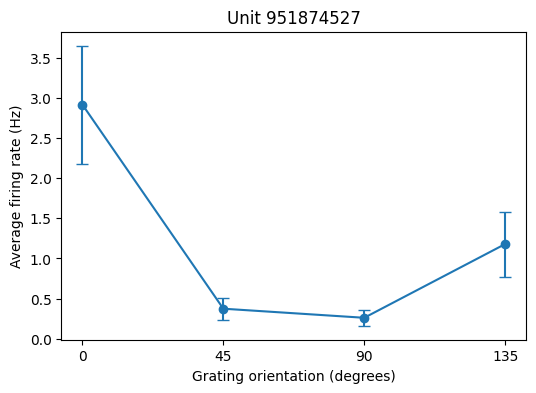

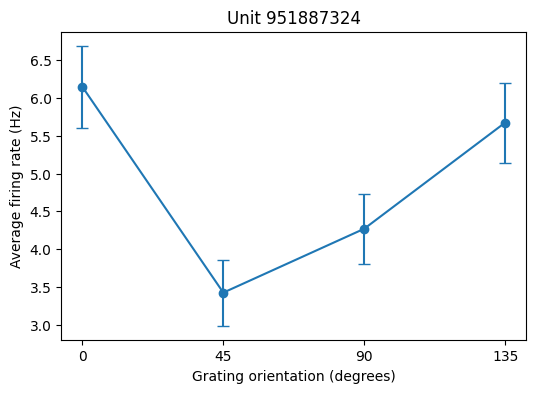

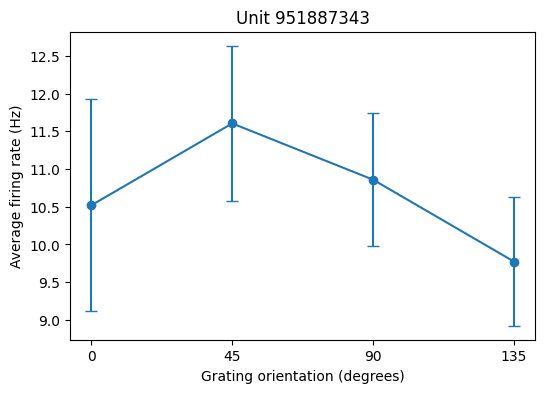

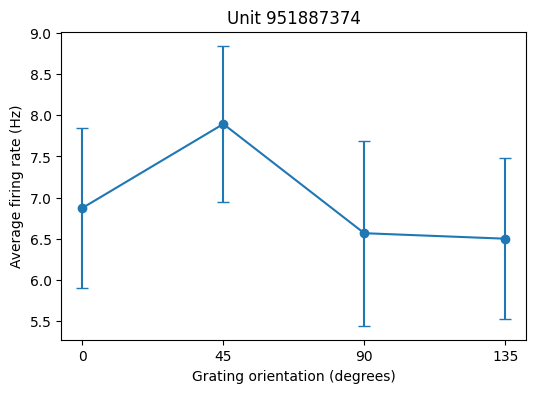

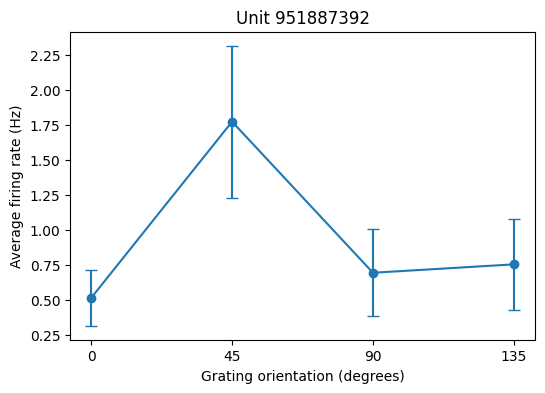

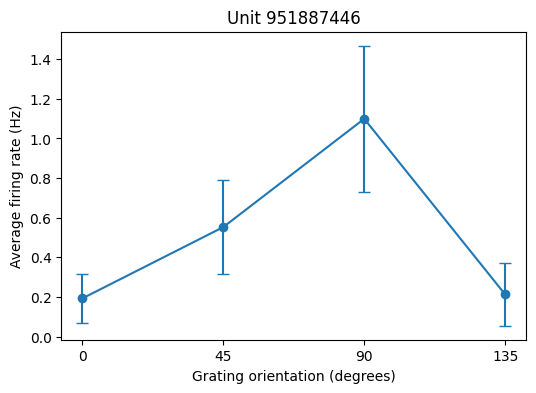

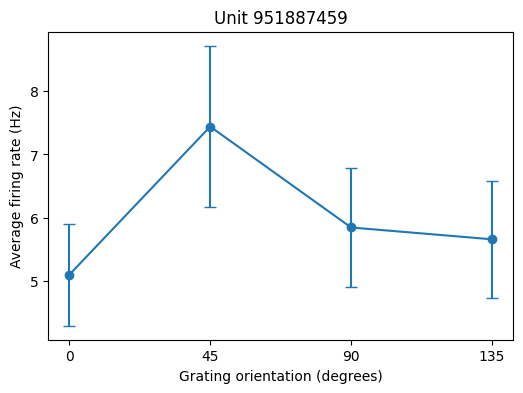

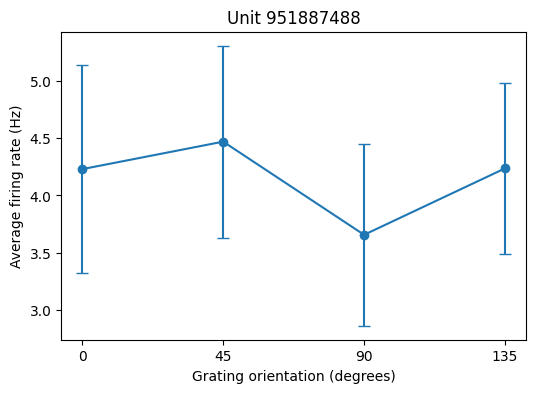

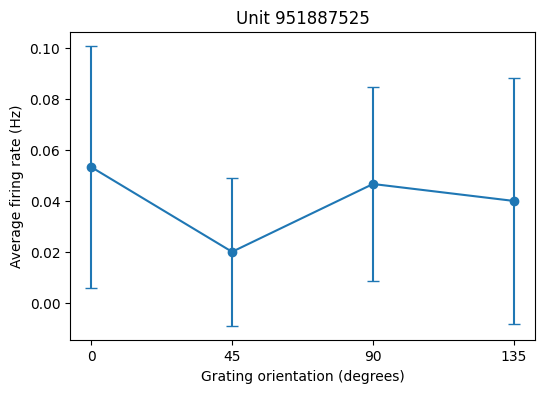

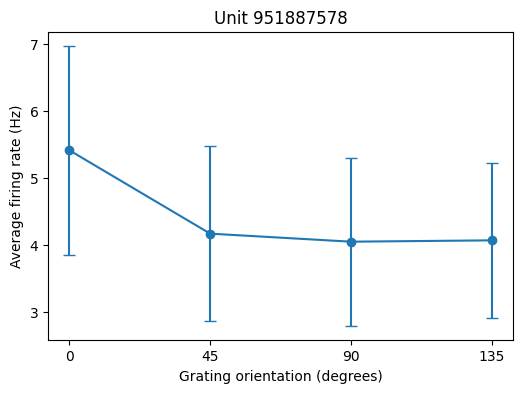

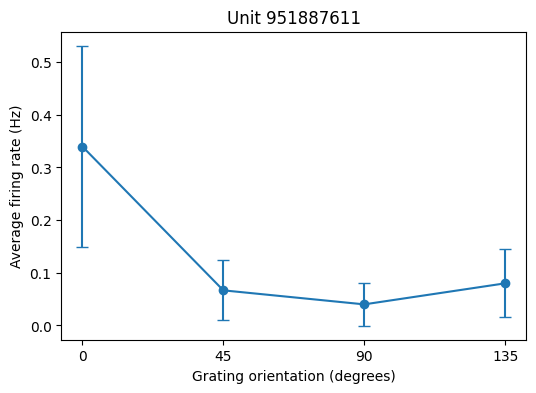

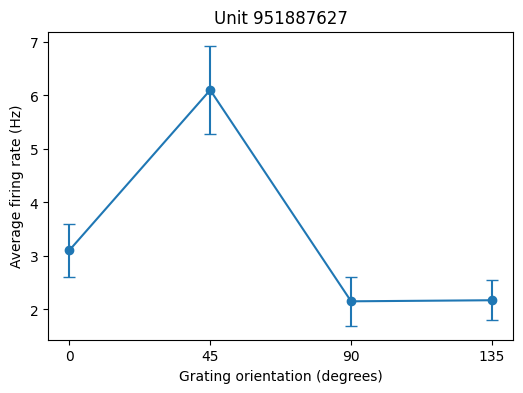

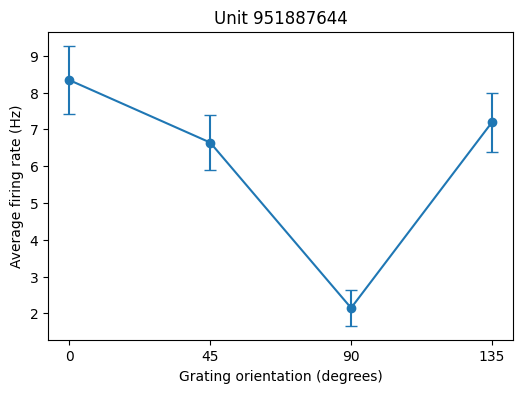

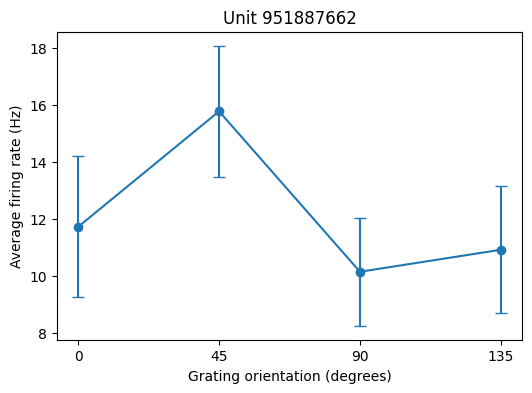

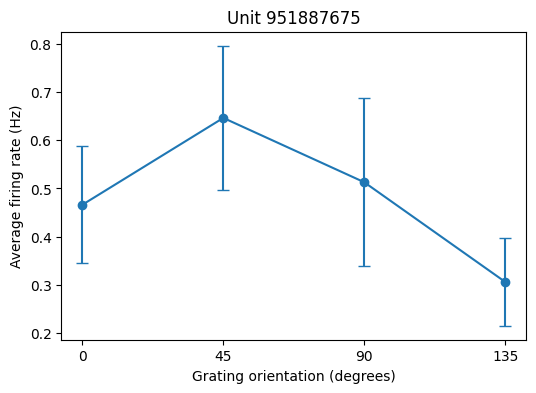

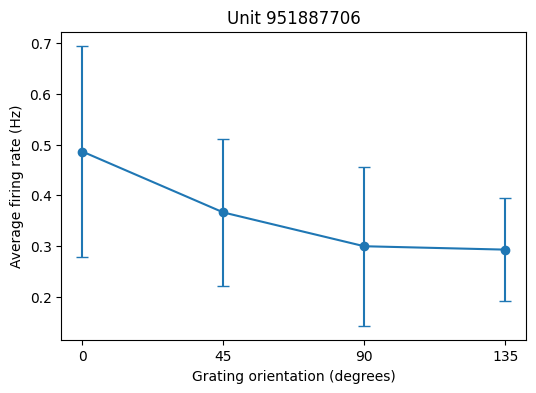

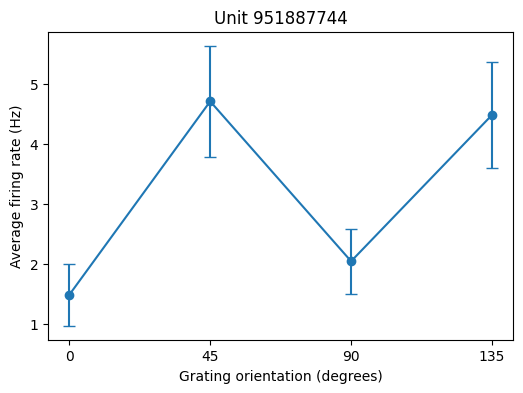

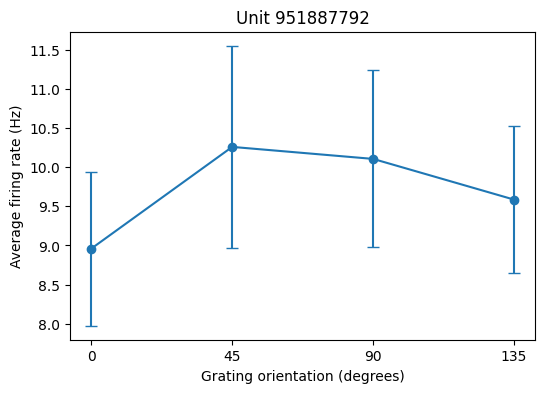

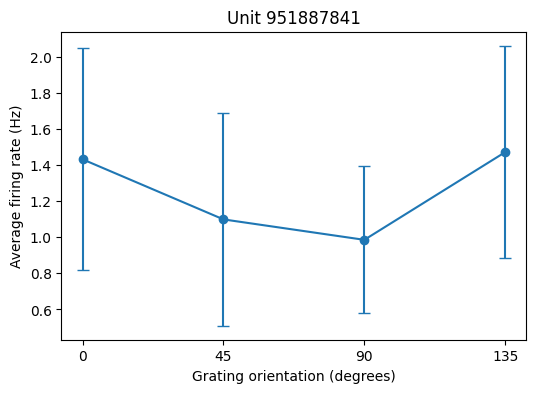

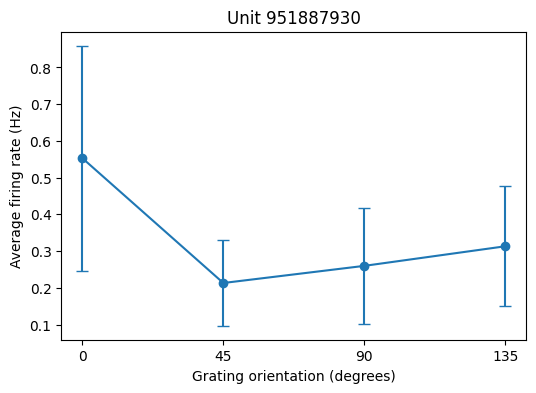

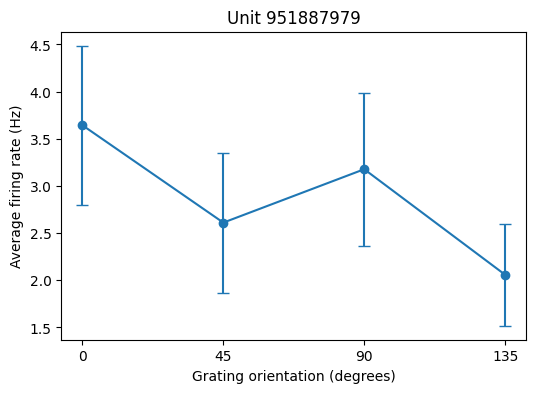

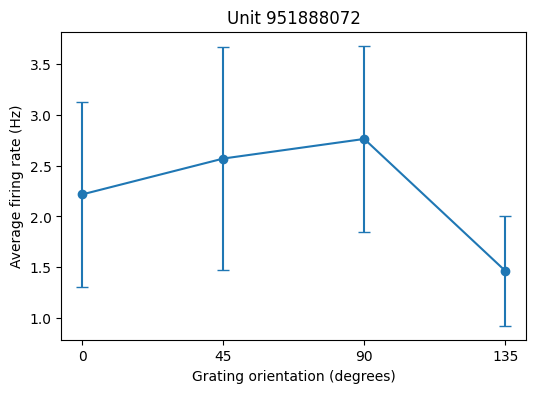

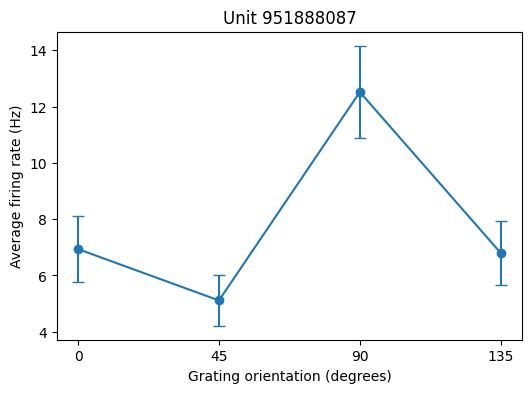

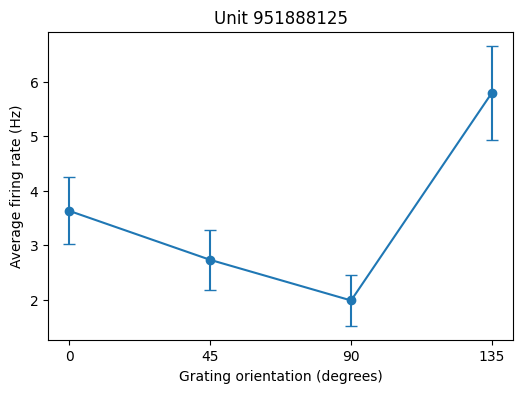

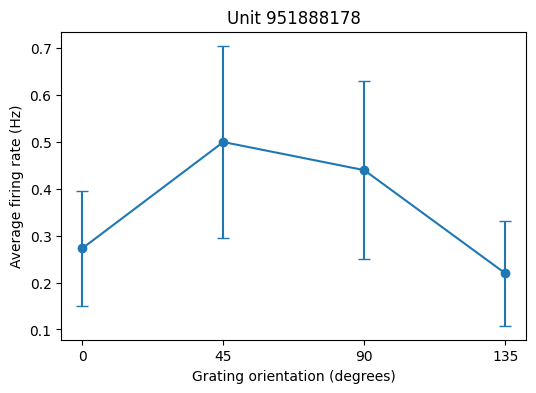

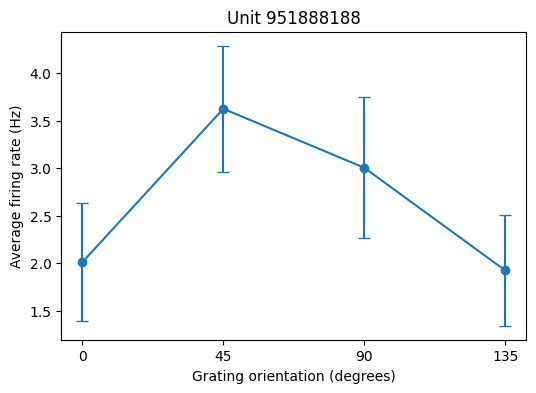

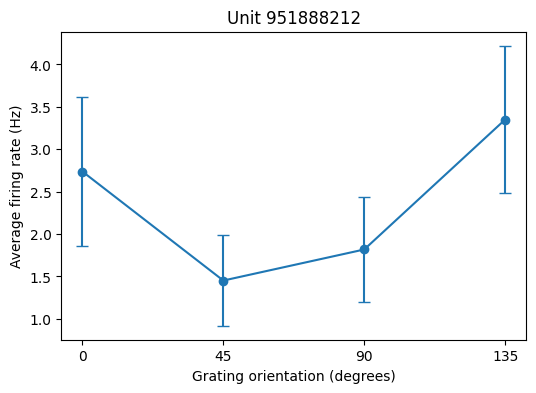

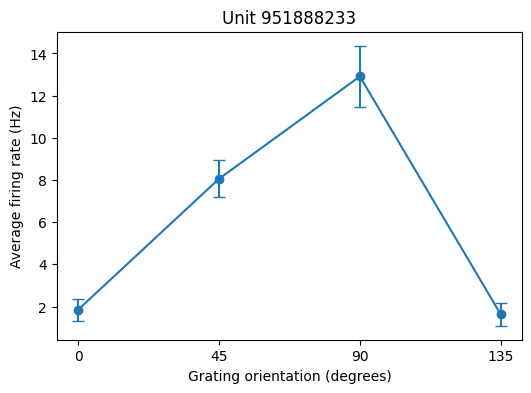

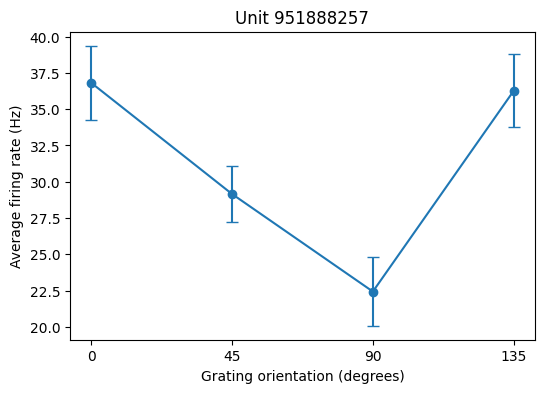

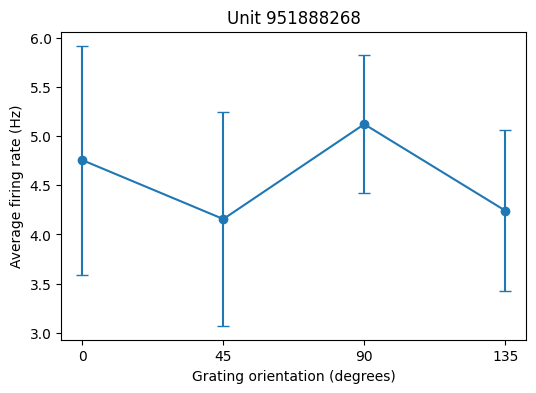

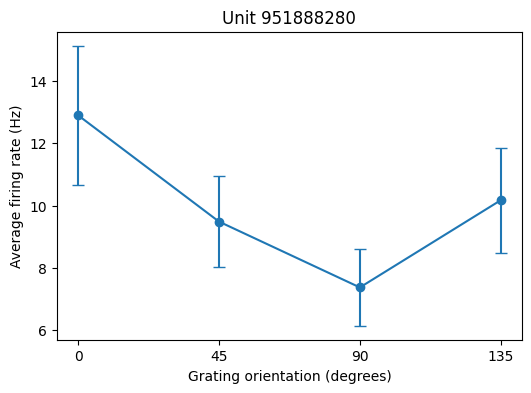

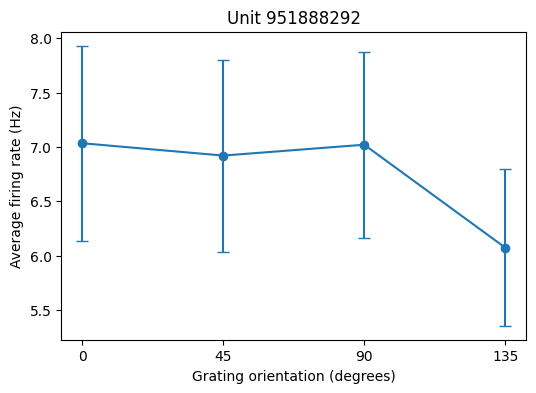

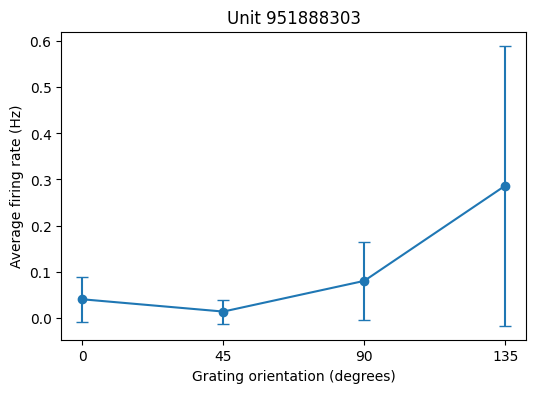

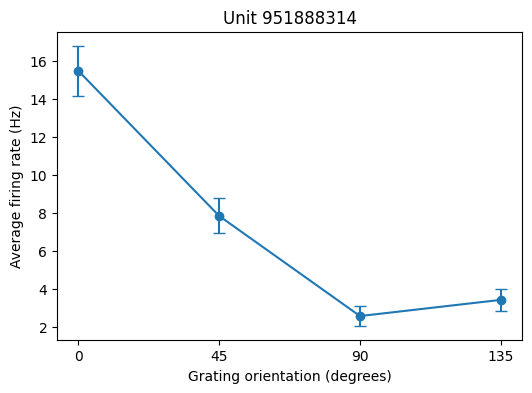

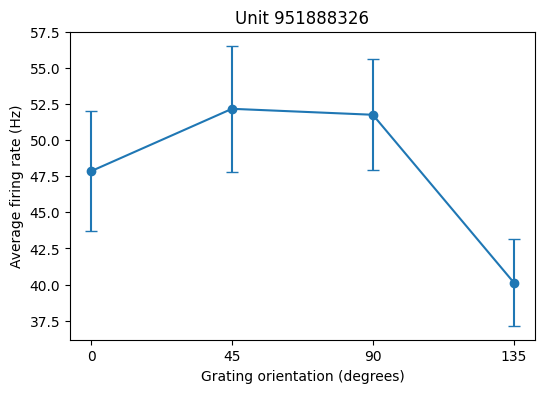

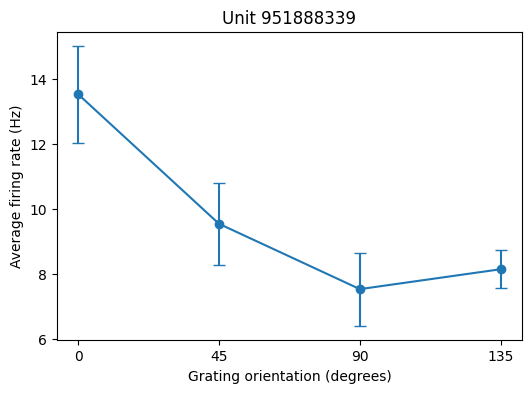

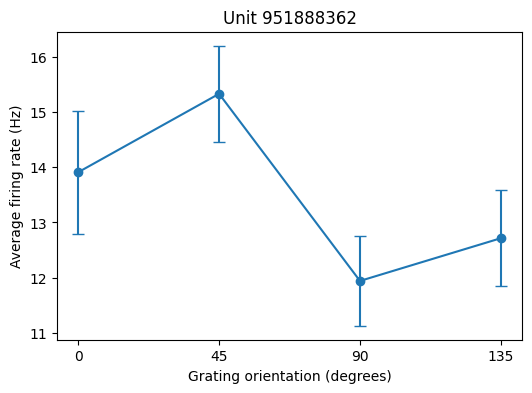

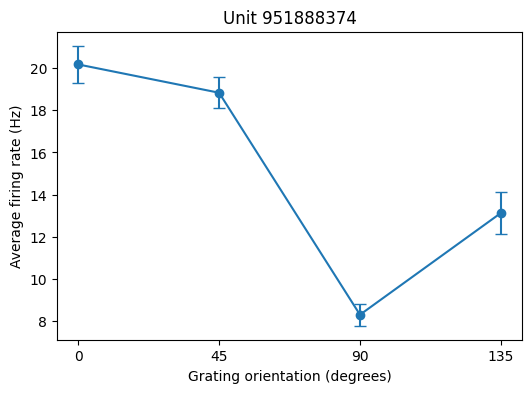

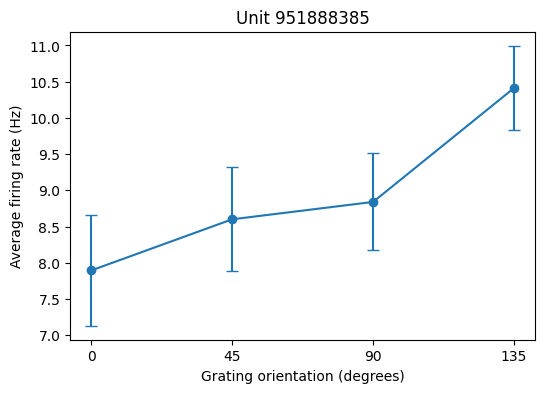

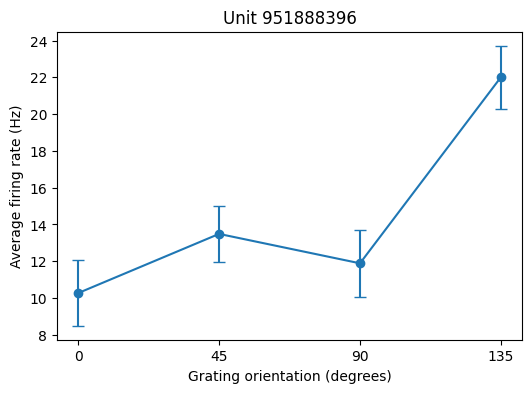

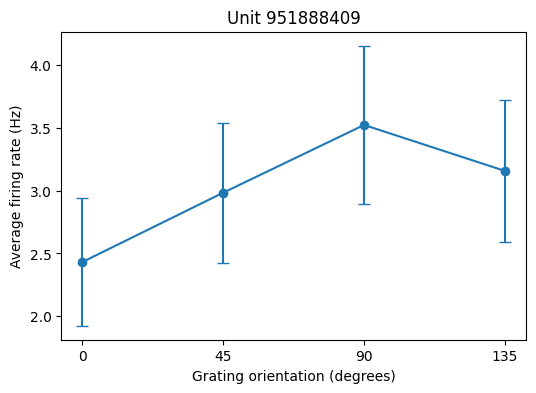

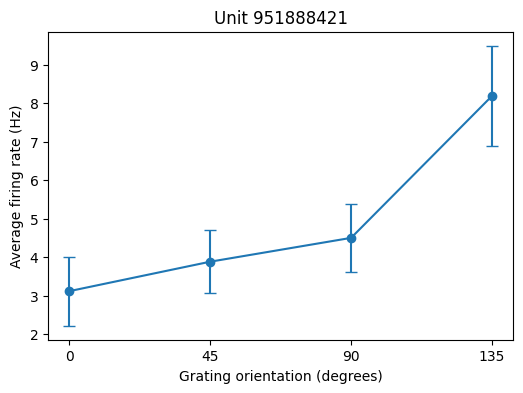

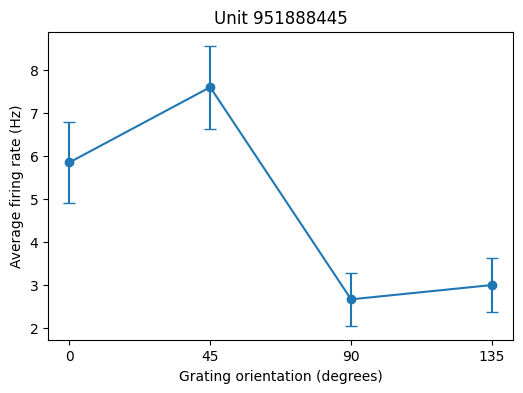

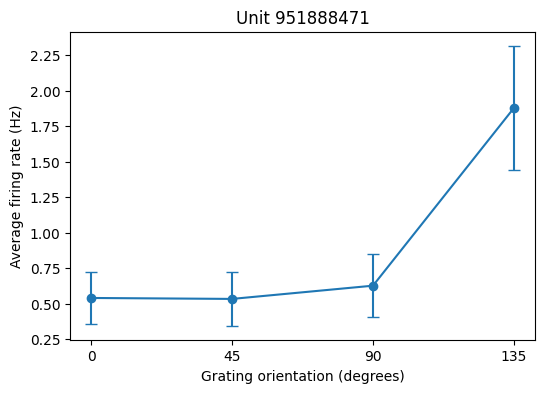

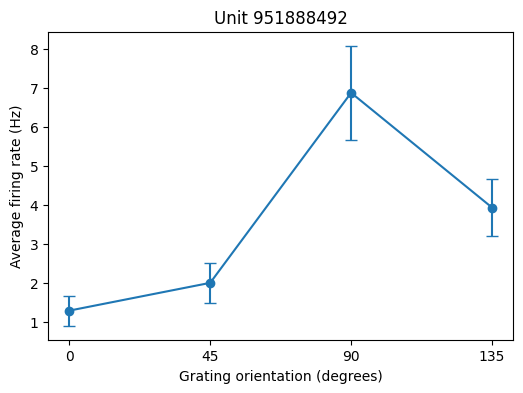

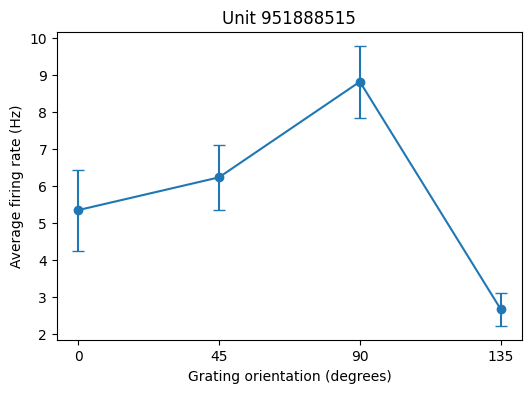

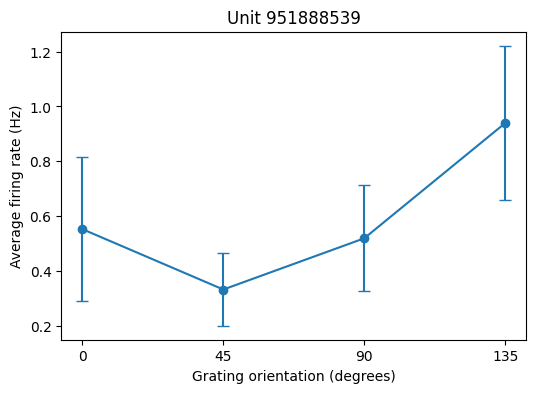

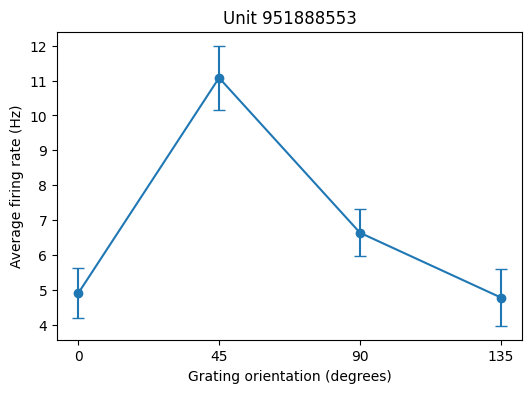

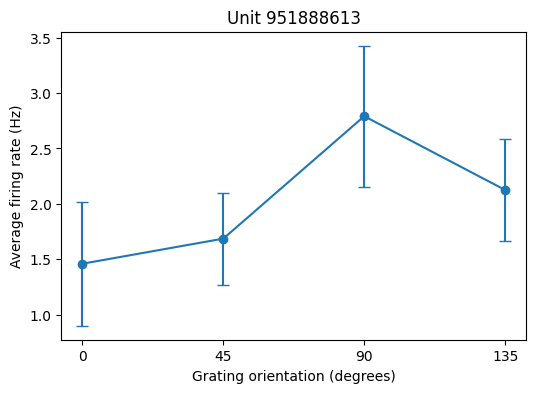

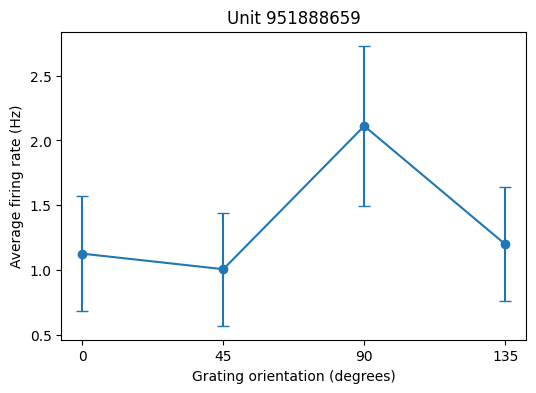

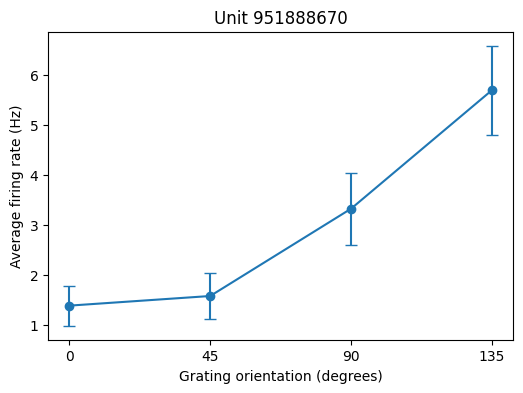

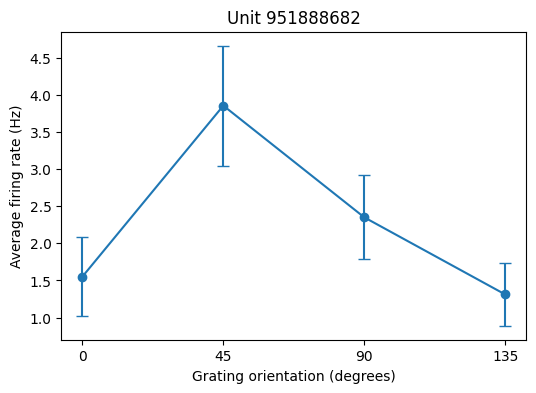

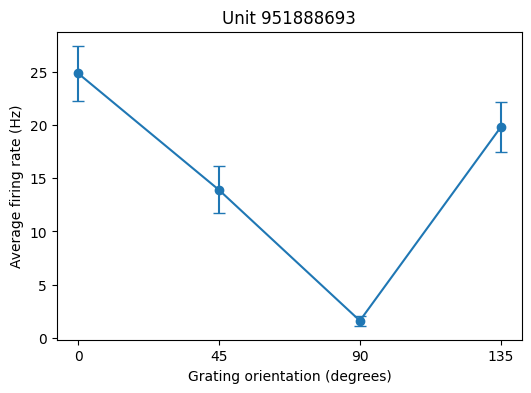

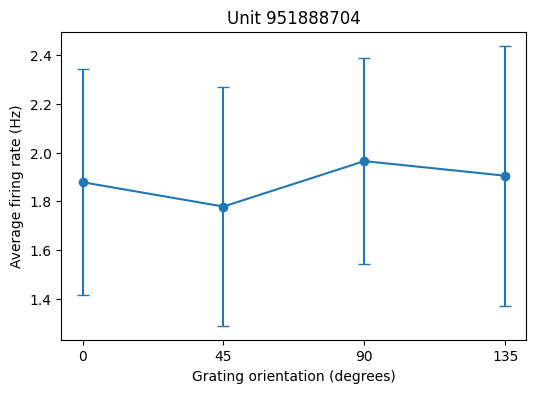

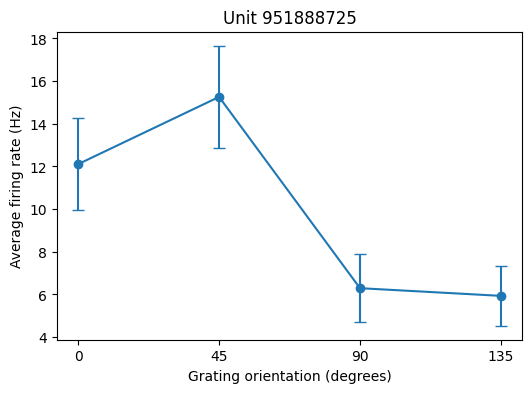

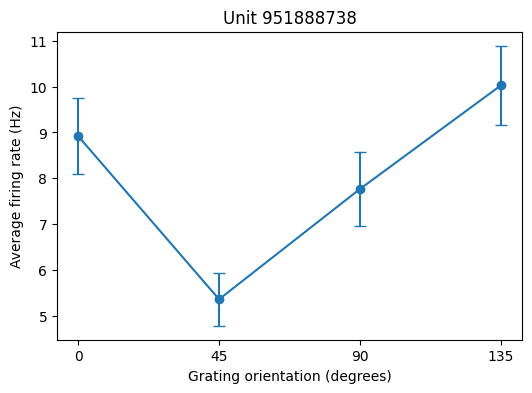

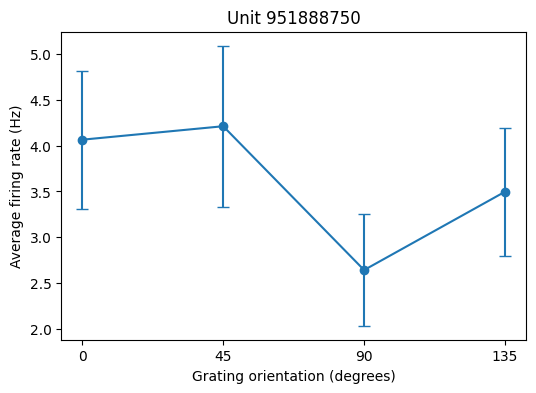

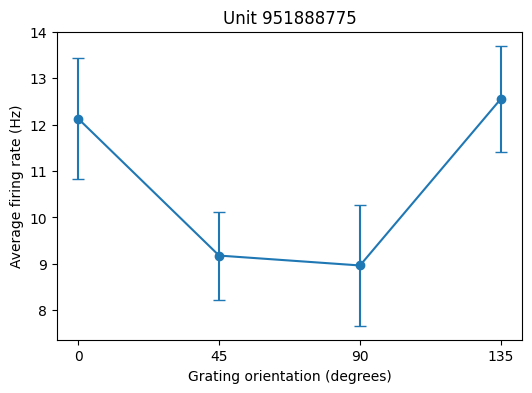

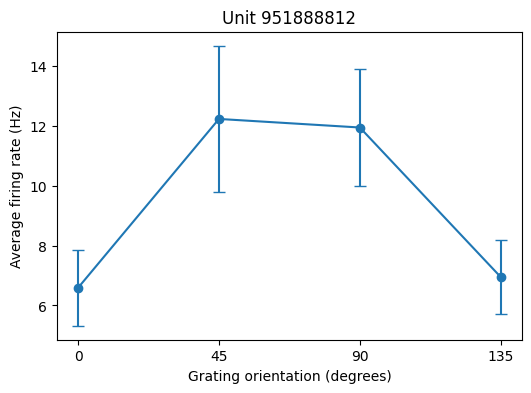

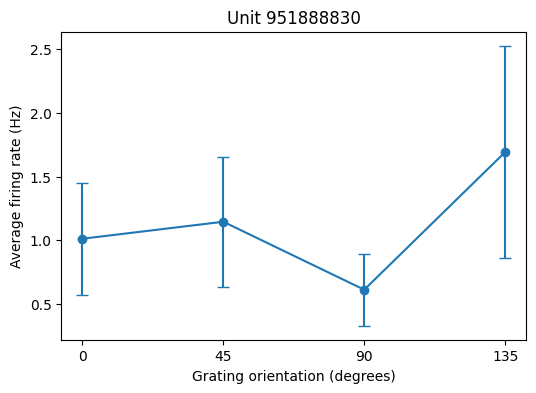

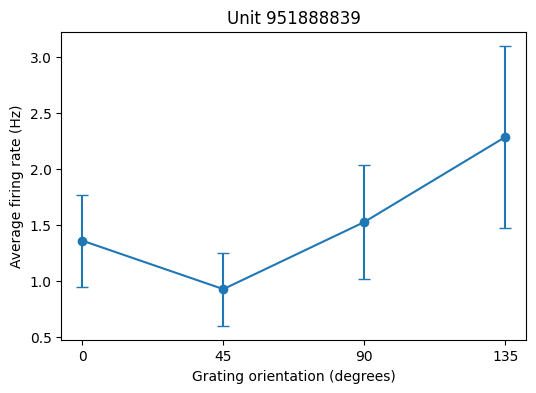

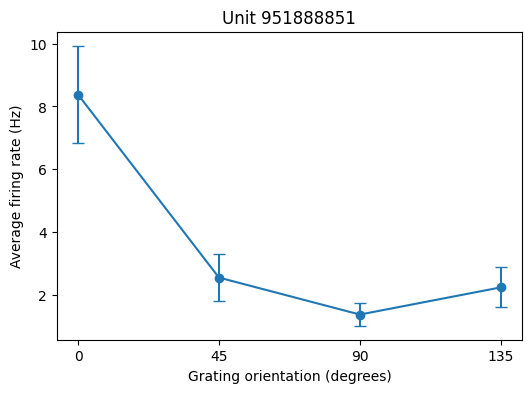

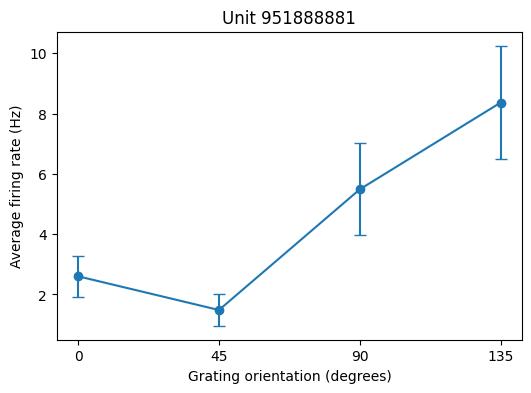

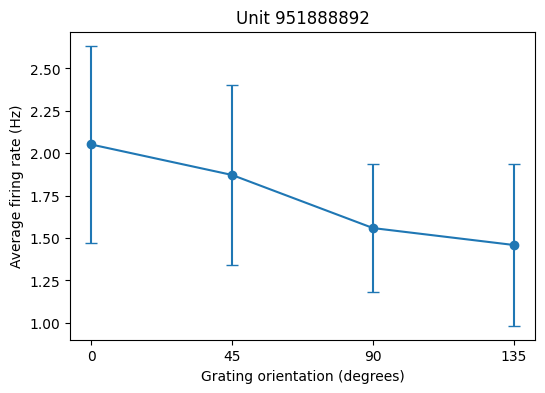

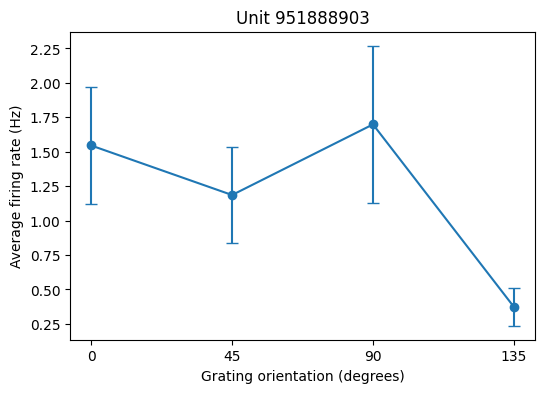

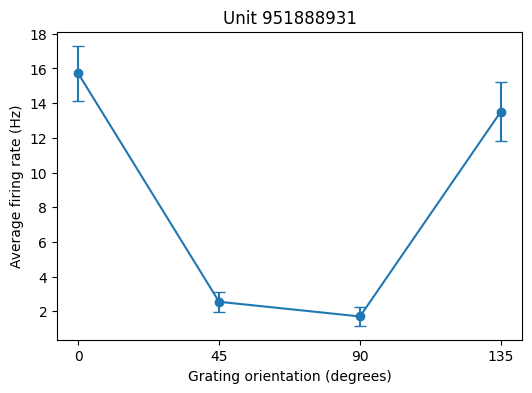

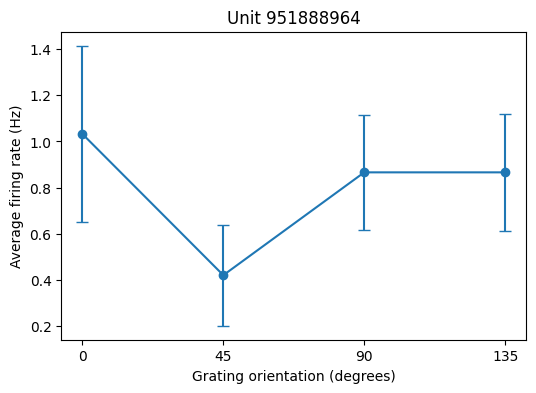

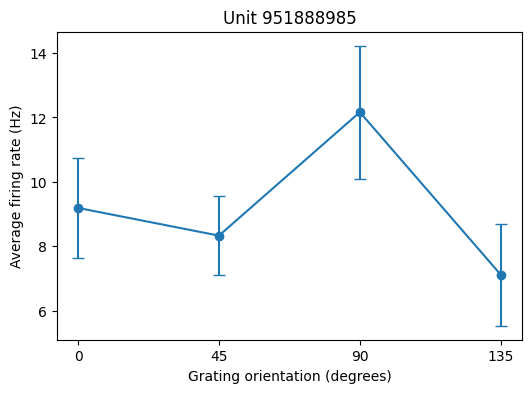

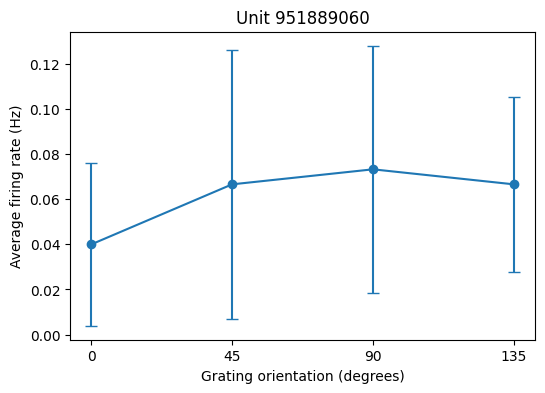

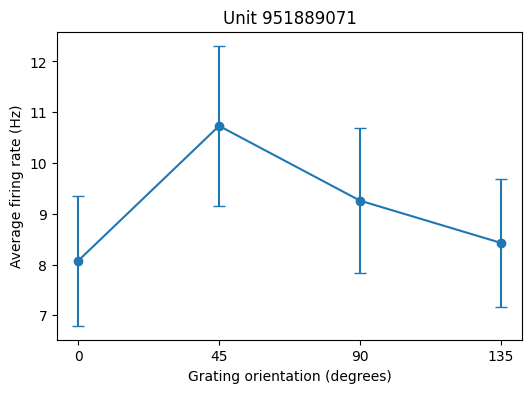

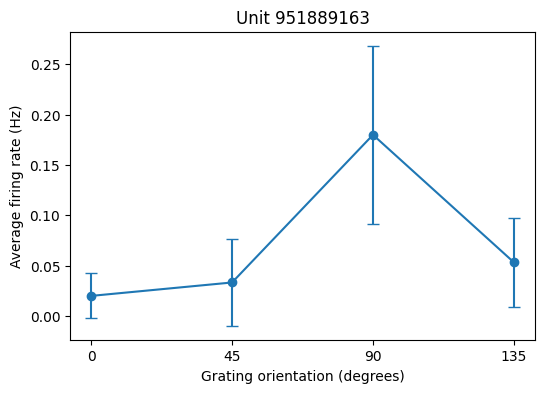

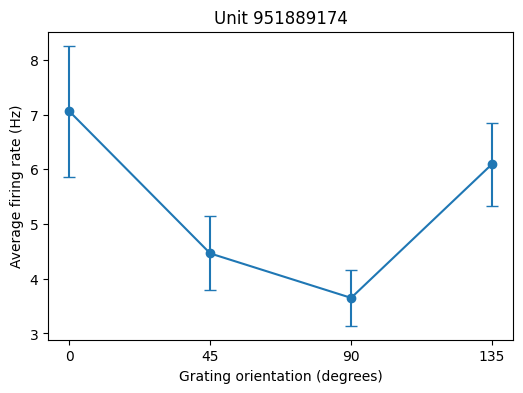

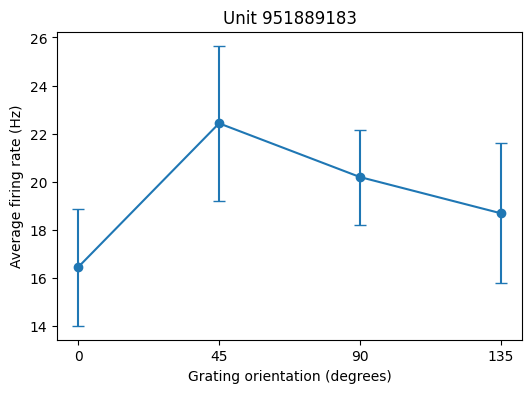

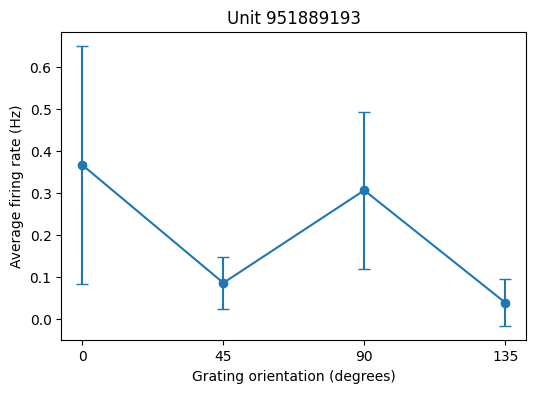

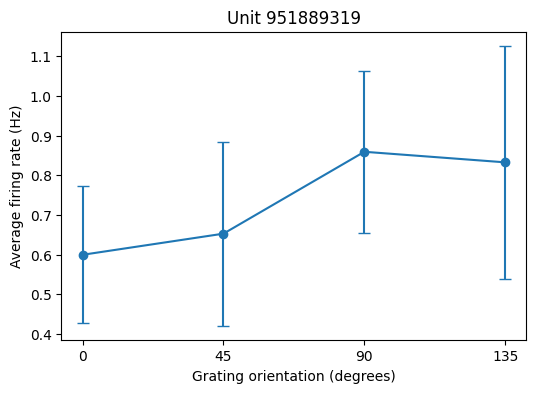

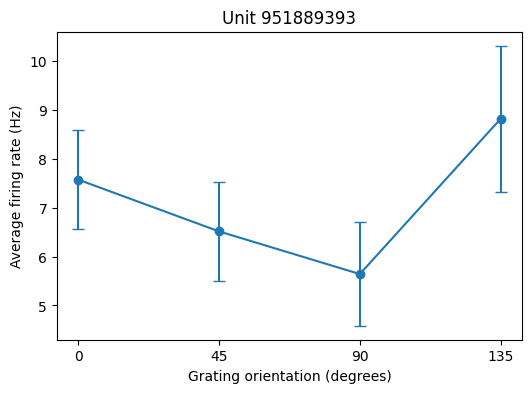

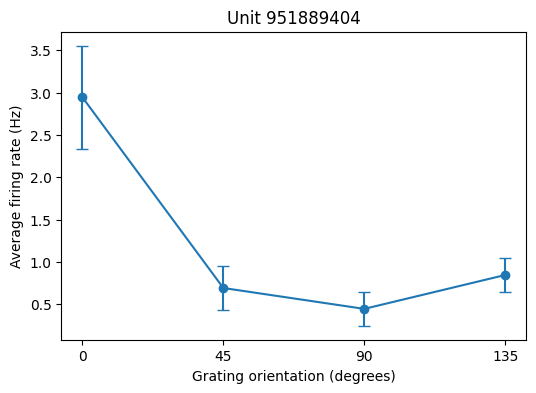

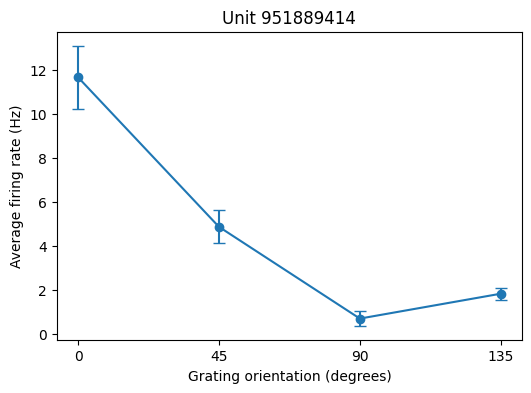

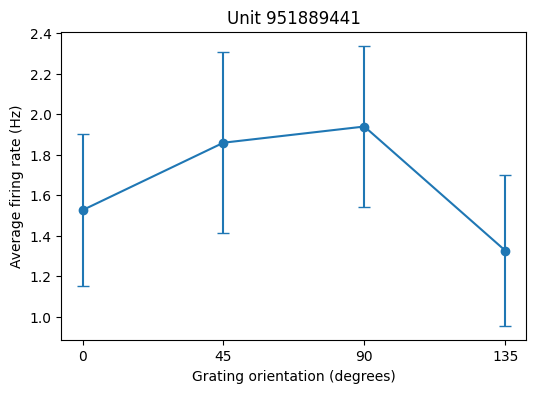

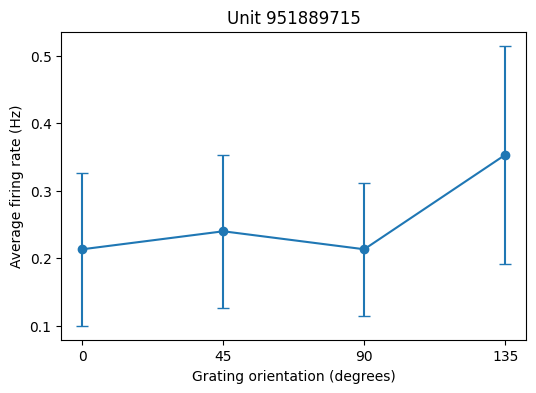

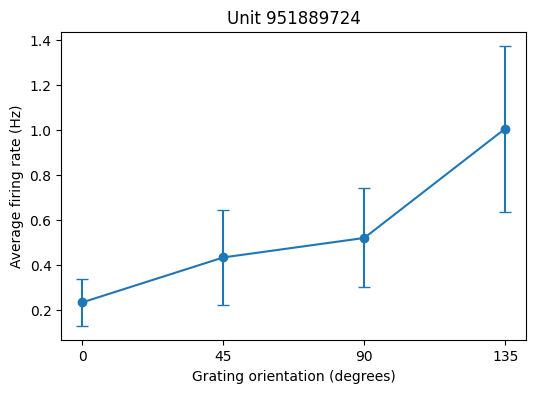

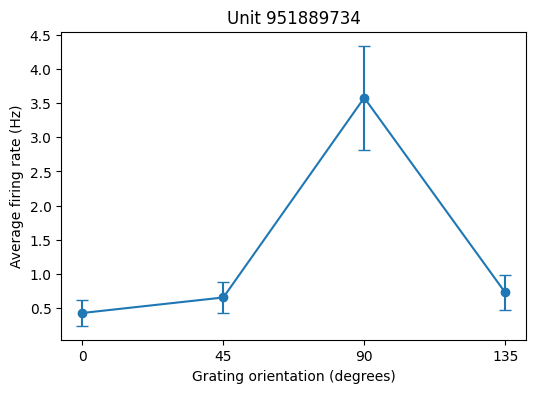

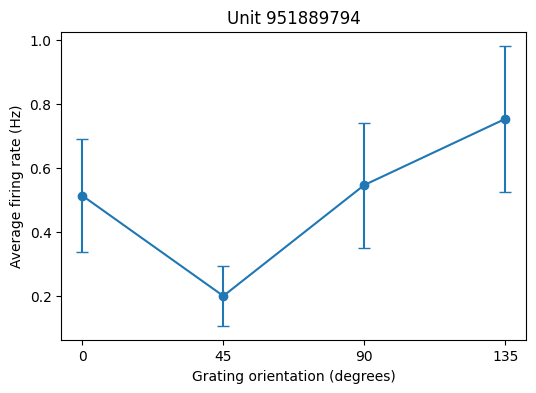

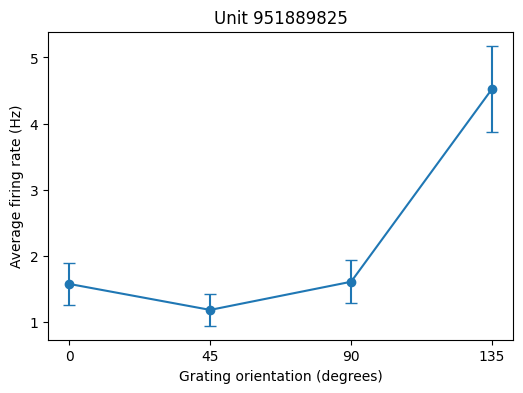

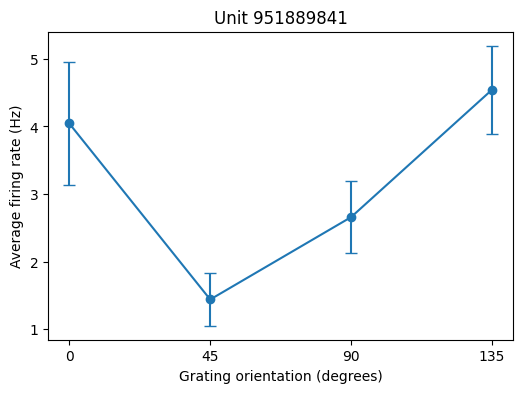

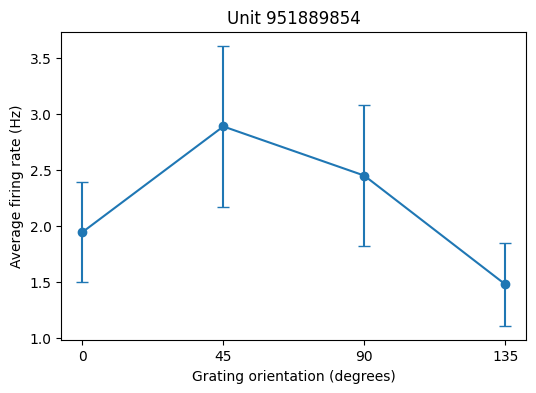

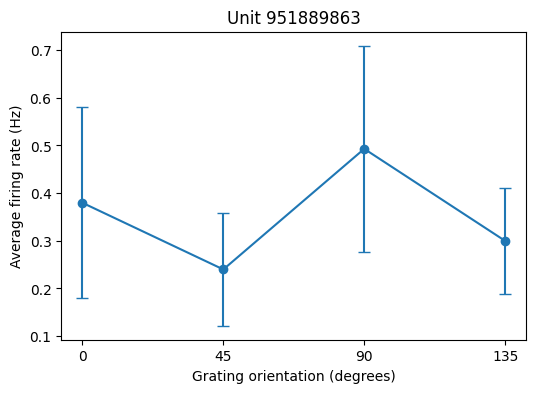

KeyboardInterrupt: 

In [67]:
import matplotlib.pyplot as plt

for unit_id in summary["unit_id"].unique():
    
    unit_data = summary[summary["unit_id"] == unit_id]
    
    plt.figure(figsize=(6, 4))
    
    plt.errorbar(
        unit_data["orientation"],
        unit_data["mean"],
        yerr=[
            unit_data["mean"] - unit_data["ci_lower"],
            unit_data["ci_upper"] - unit_data["mean"]
        ],
        marker="o",
        capsize=4
    )
    
    plt.xlabel("Grating orientation (degrees)")
    plt.ylabel("Average firing rate (Hz)")
    plt.title(f"Unit {unit_id}")
    plt.xticks([0, 45, 90, 135])
    
    plt.show()

# Decoding stimulus orientation from population activity

Two decoders read out grating orientation (0°, 45°, 90°, 135°) trial by trial from all units in one region:

1. **Linear ridge regression** predicts orientation in degrees as a continuous number; the prediction is snapped to the nearest presented orientation.
2. **Multinomial (softmax) ridge regression** gives each orientation its own weight vector and picks the most probable class.

Both models penalise the squared weights (ridge, strength α). The data are session 42 (`793224716`, `drifting_gratings_75_repeats`, 150 trials per orientation). Every split is a stratified 60 / 20 / 20 train / validation / test split. Units are z-scored using training-set statistics, α is chosen by validation accuracy (ties go to the largest α), and the chosen model is scored on the held-out test set. This is repeated over `N_SPLITS` random splits. Both models are written directly in numpy/scipy because scikit-learn isn't installed in this environment.

To run a different region, call `run_region("<acronym>")` and `report_region(...)`.

In [ ]:
from scipy import optimize, stats
from scipy.special import logsumexp

# --- Decoding configuration ---
DECODE_SESSION = 42                         # session 793224716: 150 trials per orientation
REGIONS = ["VISp", "VISal"]                 # first region analysed, then the second
ORIENTATIONS = np.array([0.0, 45.0, 90.0, 135.0])
ALPHAS = np.logspace(-2, 5, 15)             # ridge penalties tried on the validation set
N_SPLITS = 25                               # number of random train/val/test splits
SPLIT_FRACTIONS = (0.6, 0.2, 0.2)           # train / validation / test

region_units = {24: units_24_filtered, 42: units_42_filtered}

In [ ]:
def build_trial_matrix(region, session_number=DECODE_SESSION):
    """Trials x units firing-rate matrix using every unit recorded in one region."""
    unit_table = region_units[session_number]
    unit_ids = unit_table.index[unit_table["ecephys_structure_acronym"] == region]

    fr = firing_rates[
        (firing_rates["session"] == session_number) &
        (firing_rates["unit_id"].isin(unit_ids))
    ]

    X_df = fr.pivot(index="presentation_id", columns="unit_id", values="firing_rate")
    y = (
        fr.groupby("presentation_id")["orientation"].first()
        .loc[X_df.index]
        .astype(float)
        .to_numpy()
    )
    return X_df.to_numpy(), y, X_df.columns.to_numpy()


def stratified_split(y, seed, fractions=SPLIT_FRACTIONS):
    """Random train/val/test indices with equal orientation balance in each set."""
    rng = np.random.default_rng(seed)
    train, val, test = [], [], []

    for label in np.unique(y):
        idx = rng.permutation(np.flatnonzero(y == label))
        n_train = int(round(fractions[0] * len(idx)))
        n_val = int(round(fractions[1] * len(idx)))
        train.extend(idx[:n_train])
        val.extend(idx[n_train:n_train + n_val])
        test.extend(idx[n_train + n_val:])

    return np.array(train), np.array(val), np.array(test)


def zscore_from_train(X, train, val, test):
    """Z-score every unit using training-set statistics only (needed so ridge treats units equally)."""
    mu = X[train].mean(axis=0)
    sd = X[train].std(axis=0)
    sd[sd == 0] = 1.0                       # units silent on training trials stay at 0
    return [(X[i] - mu) / sd for i in (train, val, test)]

In [ ]:
# i) Ridge linear regression: predicts orientation (degrees) as a continuous number
def fit_ridge_linear(X, y, alpha):
    y_mean = y.mean()                       # X is z-scored, so the intercept is mean(y)
    w = np.linalg.solve(X.T @ X + alpha * np.eye(X.shape[1]), X.T @ (y - y_mean))
    return w, y_mean


def predict_ridge_linear(model, X):
    w, b = model
    pred = X @ w + b
    # snap the continuous prediction to the nearest presented orientation
    return ORIENTATIONS[np.argmin(np.abs(pred[:, None] - ORIENTATIONS[None, :]), axis=1)]


# ii) Ridge multinomial (softmax) regression: one weight vector per orientation
def fit_ridge_multinomial(X, y, alpha):
    n_units, K = X.shape[1], len(ORIENTATIONS)
    Y = (y[:, None] == ORIENTATIONS[None, :]).astype(float)   # one-hot targets

    def loss_and_grad(params):
        W = params[:n_units * K].reshape(n_units, K)
        b = params[n_units * K:]
        logits = X @ W + b
        log_p = logits - logsumexp(logits, axis=1, keepdims=True)
        loss = -np.sum(Y * log_p) + alpha * np.sum(W ** 2)    # neg. log-likelihood + ridge penalty
        err = np.exp(log_p) - Y
        grad_W = X.T @ err + 2 * alpha * W
        grad_b = err.sum(axis=0)
        return loss, np.concatenate([grad_W.ravel(), grad_b])

    res = optimize.minimize(
        loss_and_grad, np.zeros(n_units * K + K),
        jac=True, method="L-BFGS-B", options={"maxiter": 2000}
    )
    return res.x[:n_units * K].reshape(n_units, K), res.x[n_units * K:]


def predict_ridge_multinomial(model, X):
    W, b = model
    return ORIENTATIONS[np.argmax(X @ W + b, axis=1)]


MODELS = {
    "linear": (fit_ridge_linear, predict_ridge_linear),
    "multinomial": (fit_ridge_multinomial, predict_ridge_multinomial),
}

In [ ]:
def run_region(region, n_splits=N_SPLITS, alphas=ALPHAS):
    """Fit both decoders on n_splits random splits; ridge alpha chosen on the validation set."""
    X, y, unit_ids = build_trial_matrix(region)
    print(f"{region}: {X.shape[0]} trials x {X.shape[1]} units")

    rows = []
    val_curves = {name: np.zeros((n_splits, len(alphas))) for name in MODELS}
    weights = {name: [] for name in MODELS}

    for split in range(n_splits):
        train, val, test = stratified_split(y, seed=split)
        X_tr, X_va, X_te = zscore_from_train(X, train, val, test)

        for name, (fit, predict) in MODELS.items():
            for a, alpha in enumerate(alphas):
                model = fit(X_tr, y[train], alpha)
                val_curves[name][split, a] = np.mean(predict(model, X_va) == y[val])

            # on ties, take the largest (most regularised) alpha
            val_acc = val_curves[name][split]
            best_alpha = alphas[np.flatnonzero(val_acc == val_acc.max())[-1]]
            model = fit(X_tr, y[train], best_alpha)

            rows.append({
                "split": split,
                "model": name,
                "alpha": best_alpha,
                "test_accuracy": np.mean(predict(model, X_te) == y[test]),
            })
            weights[name].append(model[0])

    results = pd.DataFrame(rows)
    return {
        "region": region,
        "X": X,
        "y": y,
        "unit_ids": unit_ids,
        "results": results,
        "accuracy": results.pivot(index="split", columns="model", values="test_accuracy"),
        "val_curves": val_curves,
        "weights": {name: np.array(w) for name, w in weights.items()},
    }

In [ ]:
def plot_performance(res, alphas=ALPHAS):
    acc = res["accuracy"]
    chance = 1 / len(ORIENTATIONS)

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    # validation accuracy vs ridge penalty
    for name, curves in res["val_curves"].items():
        m = curves.mean(axis=0)
        s = curves.std(axis=0) / np.sqrt(len(curves))
        axes[0].plot(alphas, m, marker="o", label=name)
        axes[0].fill_between(alphas, m - s, m + s, alpha=0.2)
    axes[0].axhline(chance, color="gray", linestyle=":", label="chance")
    axes[0].set_xscale("log")
    axes[0].set_xlabel("Ridge penalty (alpha)")
    axes[0].set_ylabel("Validation accuracy")
    axes[0].set_title(f"{res['region']}: choosing alpha")
    axes[0].legend()

    # test accuracy, linear vs multinomial, one point per split
    axes[1].scatter(acc["linear"], acc["multinomial"], alpha=0.7)
    lims = [chance - 0.05, 1.02]
    axes[1].plot(lims, lims, color="black", linewidth=1)
    axes[1].axvline(chance, color="gray", linestyle=":")
    axes[1].axhline(chance, color="gray", linestyle=":")
    axes[1].set_xlim(lims)
    axes[1].set_ylim(lims)
    axes[1].set_aspect("equal")
    axes[1].set_xlabel("Linear ridge test accuracy")
    axes[1].set_ylabel("Multinomial ridge test accuracy")
    axes[1].set_title(f"{res['region']}: test accuracy per split")

    plt.tight_layout()
    plt.show()


def compare_models(res):
    """Paired Wilcoxon signed-rank test: same test sets are used by both models in each split."""
    acc = res["accuracy"]
    diff = acc["multinomial"] - acc["linear"]
    test = stats.wilcoxon(acc["multinomial"], acc["linear"])

    print(f"{res['region']} test accuracy over {len(acc)} splits (chance = {1 / len(ORIENTATIONS):.2f})")
    for name in acc.columns:
        print(f"  {name:12s} mean = {acc[name].mean():.3f}  sd = {acc[name].std():.3f}")
    print(f"  multinomial - linear: mean = {diff.mean():.3f}, "
          f"multinomial better in {(diff > 0).sum()}/{len(diff)} splits")
    print(f"  Wilcoxon signed-rank: W = {test.statistic:.1f}, p = {test.pvalue:.2g}")
    print("  chosen alpha (median):",
          res["results"].groupby("model")["alpha"].median().to_dict())
    return test

In [ ]:
def tuning_properties(X, y):
    """Mean rate per orientation, preferred orientation, selectivity, and a sort order for units."""
    tuning = np.array([X[y == o].mean(axis=0) for o in ORIENTATIONS]).T   # units x orientations
    preferred = ORIENTATIONS[np.argmax(tuning, axis=1)]
    selectivity = (tuning.max(axis=1) - tuning.min(axis=1)) / (tuning.max(axis=1) + tuning.min(axis=1) + 1e-9)
    order = np.lexsort((-selectivity, preferred))     # by preferred orientation, most selective first
    return tuning, preferred, selectivity, order


def plot_weights(res):
    X, y = res["X"], res["y"]
    tuning, preferred, selectivity, order = tuning_properties(X, y)

    w_lin = res["weights"]["linear"].mean(axis=0)              # units
    w_mn = res["weights"]["multinomial"].mean(axis=0)          # units x orientations

    norm_tuning = tuning / np.where(tuning.max(axis=1, keepdims=True) > 0,
                                    tuning.max(axis=1, keepdims=True), 1)
    labels = [f"{o:.0f}" for o in ORIENTATIONS]
    pref_colors = plt.cm.viridis(np.linspace(0, 1, len(ORIENTATIONS)))
    unit_colors = pref_colors[np.searchsorted(ORIENTATIONS, preferred[order])]

    # --- unit-by-unit view, all panels share the same unit order ---
    fig, axes = plt.subplots(1, 3, figsize=(13, 8), sharey=True,
                             gridspec_kw={"width_ratios": [1, 1, 1.2]})

    axes[0].imshow(norm_tuning[order], aspect="auto", cmap="viridis", interpolation="nearest")
    axes[0].set_title("Tuning (rate / max rate)")
    axes[0].set_xlabel("Stimulus orientation")
    axes[0].set_ylabel("Units (sorted by preferred orientation)")

    vmax = np.abs(w_mn).max()
    im = axes[1].imshow(w_mn[order], aspect="auto", cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                        interpolation="nearest")
    axes[1].set_title("Multinomial weights")
    axes[1].set_xlabel("Decoder class (orientation)")
    fig.colorbar(im, ax=axes[1], fraction=0.05)

    for ax in axes[:2]:
        ax.set_xticks(range(len(ORIENTATIONS)))
        ax.set_xticklabels(labels)

    axes[2].barh(np.arange(len(order)), w_lin[order], color=unit_colors, height=1.0)
    axes[2].axvline(0, color="black", linewidth=0.8)
    axes[2].set_title("Linear weights (colour = preferred orientation)")
    axes[2].set_xlabel("Weight (deg per s.d. of firing rate)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=c) for c in pref_colors]
    axes[2].legend(handles, labels, title="Preferred", loc="lower right")

    fig.suptitle(f"{res['region']}: decoder weights vs. tuning ({len(order)} units, mean over splits)")
    plt.tight_layout()
    plt.show()

    # --- summary by preferred-orientation group ---
    groups = [preferred == o for o in ORIENTATIONS]
    group_mn = np.array([w_mn[g].mean(axis=0) for g in groups])                 # preferred x class
    group_lin = np.array([w_lin[g].mean() for g in groups])
    group_lin_sem = np.array([w_lin[g].std() / np.sqrt(max(g.sum(), 1)) for g in groups])
    n_per_group = [g.sum() for g in groups]

    fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

    vmax = np.abs(group_mn).max()
    im = axes[0].imshow(group_mn, cmap="RdBu_r", vmin=-vmax, vmax=vmax)
    axes[0].set_xticks(range(len(ORIENTATIONS)))
    axes[0].set_xticklabels(labels)
    axes[0].set_yticks(range(len(ORIENTATIONS)))
    axes[0].set_yticklabels([f"{l} (n={n})" for l, n in zip(labels, n_per_group)])
    axes[0].set_xlabel("Decoder class (orientation)")
    axes[0].set_ylabel("Units' preferred orientation")
    axes[0].set_title("Mean multinomial weight")
    fig.colorbar(im, ax=axes[0])

    axes[1].bar(labels, group_lin, yerr=group_lin_sem, color=pref_colors, capsize=4)
    axes[1].axhline(0, color="black", linewidth=0.8)
    axes[1].set_xlabel("Units' preferred orientation")
    axes[1].set_ylabel("Mean linear weight (Â± SEM across units)")
    axes[1].set_title("Mean linear weight")

    fig.suptitle(f"{res['region']}: weights grouped by preferred orientation")
    plt.tight_layout()
    plt.show()

    return pd.DataFrame(group_mn, index=pd.Index(ORIENTATIONS, name="preferred"),
                        columns=pd.Index(ORIENTATIONS, name="decoder class"))


def report_region(res):
    plot_performance(res)
    compare_models(res)
    return plot_weights(res)

## Region 1: VISp

In [ ]:
decoding = {}
decoding["VISp"] = run_region("VISp")
report_region(decoding["VISp"])

### Interpretation (VISp)

**Performance.** Both decoders are far above chance (0.25). The multinomial decoder is almost perfect (~0.99), while the linear decoder reaches ~0.90. The multinomial model wins on every split. The paired Wilcoxon signed-rank test is significant (p ≈ 6e-8 with 25 splits).

*Why a paired Wilcoxon test?* In each split both models are scored on exactly the same test trials, so the comparison is paired. Accuracies are bounded, discrete and near ceiling, so a non-parametric test is safer than a t-test. Caveat: the random splits re-use trials, so they are not fully independent and the p-value is optimistic. Still, the effect is consistent in direction and size across all splits.

**Why the multinomial model is better.** Linear regression assumes orientation is a *monotonic, linear* function of the population response, with one axis running from 0° to 135°. Orientation tuning is not like that:
- Tuning curves are **peaked**. A unit that prefers 45° fires more at 45° than at both 0° and 90°, so a single linear weight can't use it to push the prediction in a consistent direction.
- Orientation is **circular**. 0° and 135° are only 45° apart, yet the linear readout has to place them at opposite ends of its axis.
- The squared-error loss treats predicting 90° for a 0° trial as worse than predicting 45°, even though both are simply wrong for classification.

The multinomial model learns a separate template for each orientation, so peaked tuning is exactly what it needs.

**Weights.** Sort units by preferred orientation and compare with the tuning heatmap:
- **Multinomial:** the weights form a block diagonal. The weight vector for class θ is positive for units that prefer θ and negative for units that prefer other orientations. Each class detector is essentially a matched filter for its population of preferring units, and the grouped-weights matrix shows a positive diagonal with negative off-diagonal entries.
- **Linear:** the mean weight rises with preferred orientation. It is negative for 0°-preferring units, near zero for 45°, and positive for 90° and 135°. The decoder uses the 0° and 135° populations as opposing "ends" of its axis and largely ignores 45°-preferring units, which aren't monotonic. Intermediate orientations are decoded by a weighted balance of the two ends, and that's where its errors occur.

## Region 2: VISal

In [ ]:
decoding["VISal"] = run_region("VISal")
report_region(decoding["VISal"])

### Interpretation (VISal)

The same pattern holds. Multinomial (~0.99) beats linear (~0.72) on every split, again with p ≈ 6e-8.

The gap is much larger than in VISp, even though VISal has about twice as many units. The multinomial decoder is still near ceiling, so orientation information is clearly present in VISal. The linear readout loses more because VISal tuning is broader and weaker, which makes a single monotonic axis a worse fit. The validation curve also shows that the linear model needs more regularisation here (larger α).

The weights tell the same story as VISp. The multinomial weights are diagonal (each class detector weights its preferring units positively). The linear weights again go from negative (0°-preferring) through roughly zero (45°) to positive (90°/135°).

## Comparing regions

In [ ]:
pd.DataFrame({
    region: {
        "n_units": res["X"].shape[1],
        "linear_accuracy": res["accuracy"]["linear"].mean(),
        "multinomial_accuracy": res["accuracy"]["multinomial"].mean(),
        "wilcoxon_p": stats.wilcoxon(res["accuracy"]["multinomial"], res["accuracy"]["linear"]).pvalue,
    }
    for region, res in decoding.items()
}).T